
CRUSH SINGLE-CELL UMAP

Chromosome : chr1
Resolution : 25kb

Matrix:
hippo_cortex_25kb_chr1.txt

Metadata:
metadata.cells_contacts_100k.txt

Output directory:
25kb


ADDITIONAL CELL TYPES DETECTED

'Cortical L2–5 Pyramidal Cell'                     n=228

These categories will be retained separately.

METADATA SUMMARY

Total metadata cells: 1954

Region counts:
Region
Cortex         1075
Hippocampus     879

Cell-type mapping and counts:

 0  Neonatal Neuron 1                        346
 1  Neonatal Neuron 2                        239
 2  Medium Spiny Neuron                      37
 3  Interneuron                              111
 4  Hippocampal Granule Cell                 136
 5  Hippocampal Pyramidal Cell               189
 6  Cortical L2-L5 Pyramidal Cell            0
 7  Neonatal Astrocyte                       75
 8  Adult Astrocyte                          93
 9  Cortical L6 Pyramidal Cell               94
10  Microglia Etc.                           108
11  Mature Oligodendroc

site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(



Embedding dimensions: (1482, 2)

Saved UMAP coordinates:
UMAP_hippo_cortex_CRUSH_25kb_chr1_noBulk.csv

Saved PNG:
UMAP_hippo_cortex_CRUSH_25kb_chr1_celltypes.png

Saved PDF:
UMAP_hippo_cortex_CRUSH_25kb_chr1_celltypes.pdf


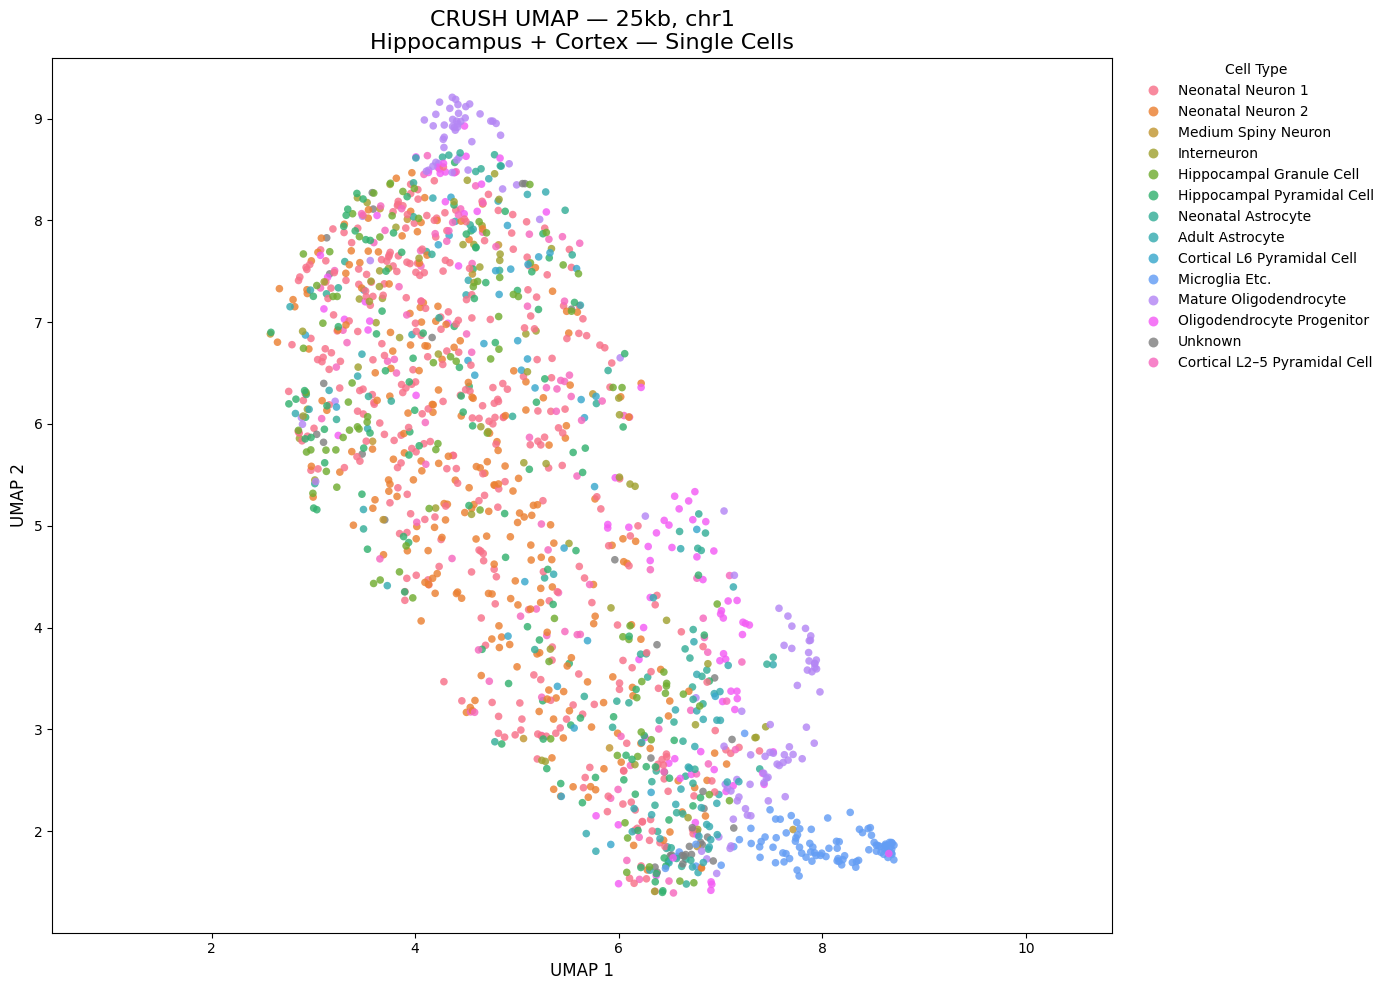


CELL TYPES IN FINAL UMAP

 0  Neonatal Neuron 1                        345
 1  Neonatal Neuron 2                        238
 2  Medium Spiny Neuron                      12
 3  Interneuron                              63
 4  Hippocampal Granule Cell                 91
 5  Hippocampal Pyramidal Cell               121
 7  Neonatal Astrocyte                       75
 8  Adult Astrocyte                          67
 9  Cortical L6 Pyramidal Cell               36
10  Microglia Etc.                           93
11  Mature Oligodendrocyte                   114
12  Oligodendrocyte Progenitor               91
13  Unknown                                  37
14  Cortical L2–5 Pyramidal Cell             99

Region counts in final UMAP:

Region
Cortex         765
Hippocampus    717

ANALYSIS COMPLETE

Chromosome             : chr1
Resolution             : 25kb

Original metadata cells: 1954
Excluded all-NA cells  : 472
Cells in final UMAP    : 1482

All-NA bins removed    : 0
Zero-variance removed  

In [5]:
import os
import re
import unicodedata

import numpy as np
import pandas as pd

import umap.umap_ as umap

from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler

import matplotlib.pyplot as plt
import seaborn as sns


CHROMOSOME = "1"

RESOLUTION_BP = 25000


UMAP_N_NEIGHBORS = 15

UMAP_MIN_DIST = 0.01

UMAP_METRIC = "cosine"

UMAP_RANDOM_STATE = 42


KNN_NEIGHBORS = 5


RESOLUTION_LABELS = {

    25000: "25kb",

    50000: "50kb",

    100000: "100kb",

}


if RESOLUTION_BP not in RESOLUTION_LABELS:

    raise ValueError(

        f"Unsupported resolution: {RESOLUTION_BP}\n"

        f"Choose one of: "
        f"{list(RESOLUTION_LABELS.keys())}"

    )


RESOLUTION = RESOLUTION_LABELS[
    RESOLUTION_BP
]


CHROMOSOME = str(
    CHROMOSOME
).strip()


if CHROMOSOME.lower().startswith(
    "chr"
):

    CHROMOSOME = CHROMOSOME[3:]


if CHROMOSOME == "":

    raise ValueError(
        "CHROMOSOME cannot be empty."
    )


BASE_DIR = (

    "GIscores_vs_Eigen/"
    "OnepunchMan/Published/redo_DipC_RUST/"
    "hippo_cortex"

)


matrix_file = os.path.join(

    BASE_DIR,

    "crush",

    f"combined_chr{CHROMOSOME}",

    f"hippo_cortex_{RESOLUTION}_chr{CHROMOSOME}.txt"

)


metadata_file = os.path.join(

    BASE_DIR,

    "metadata.cells_contacts_100k.txt"

)


output_dir = os.path.join(

    BASE_DIR,

    "analysis",

    f"chr{CHROMOSOME}",

    RESOLUTION

)


os.makedirs(
    output_dir,
    exist_ok=True
)


output_csv = os.path.join(

    output_dir,

    (
        f"UMAP_hippo_cortex_CRUSH_"
        f"{RESOLUTION}_chr{CHROMOSOME}_noBulk.csv"
    )

)


excluded_cells_file = os.path.join(

    output_dir,

    (
        f"excluded_allNA_cells_"
        f"{RESOLUTION}_chr{CHROMOSOME}.csv"
    )

)


missingness_file = os.path.join(

    output_dir,

    (
        f"cell_missingness_"
        f"{RESOLUTION}_chr{CHROMOSOME}.csv"
    )

)


plot_png = os.path.join(

    output_dir,

    (
        f"UMAP_hippo_cortex_CRUSH_"
        f"{RESOLUTION}_chr{CHROMOSOME}_celltypes.png"
    )

)


plot_pdf = os.path.join(

    output_dir,

    (
        f"UMAP_hippo_cortex_CRUSH_"
        f"{RESOLUTION}_chr{CHROMOSOME}_celltypes.pdf"
    )

)


BASE_CELL_TYPE_ORDER = [

    "Neonatal Neuron 1",

    "Neonatal Neuron 2",

    "Medium Spiny Neuron",

    "Interneuron",

    "Hippocampal Granule Cell",

    "Hippocampal Pyramidal Cell",

    "Cortical L2-L5 Pyramidal Cell",

    "Neonatal Astrocyte",

    "Adult Astrocyte",

    "Cortical L6 Pyramidal Cell",

    "Microglia Etc.",

    "Mature Oligodendrocyte",

    "Oligodendrocyte Progenitor",

    "Unknown",

]


print()
print("============================================================")
print("CRUSH SINGLE-CELL UMAP")
print("============================================================")

print()

print(
    "Chromosome :",
    f"chr{CHROMOSOME}"
)

print(
    "Resolution :",
    RESOLUTION
)

print()

print(
    "Matrix:"
)

print(
    matrix_file
)

print()

print(
    "Metadata:"
)

print(
    metadata_file
)

print()

print(
    "Output directory:"
)

print(
    output_dir
)

print()

print("============================================================")


if not os.path.isfile(
    matrix_file
):

    raise FileNotFoundError(

        "CRUSH matrix was not found:\n\n"

        f"{matrix_file}"

    )


if not os.path.isfile(
    metadata_file
):

    raise FileNotFoundError(

        "Metadata file was not found:\n\n"

        f"{metadata_file}"

    )


labels = pd.read_csv(

    metadata_file,

    header=None,

    sep="\t",

    usecols=[0, 1],

    names=[
        "UniqueID",
        "CellType"
    ],

    dtype=str

)


labels = labels[
    labels["UniqueID"].notna()
].copy()


labels["UniqueID"] = (

    labels["UniqueID"]
    .astype(str)
    .str.strip()

)


labels = labels[
    labels["UniqueID"] != ""
].copy()


labels = labels.reset_index(
    drop=True
)


def clean_cell_type(value):

    if pd.isna(
        value
    ):

        return "Unknown"


    value = str(
        value
    )


    value = unicodedata.normalize(
        "NFKC",
        value
    )


    value = re.sub(

        r"\s+",

        " ",

        value

    )


    value = value.strip()


    if value.casefold() in {

        "",

        "na",

        "n/a",

        "nan",

        "none",

        "null",

        "unknown",

    }:

        return "Unknown"


    return value


labels["CellType"] = (

    labels["CellType"]
    .apply(
        clean_cell_type
    )

)


canonical_lookup = {

    cell_type.casefold():
    cell_type

    for cell_type
    in BASE_CELL_TYPE_ORDER

}


def canonicalize_cell_type(
    value
):

    lookup_value = (
        value.casefold()
    )


    if lookup_value in canonical_lookup:

        return canonical_lookup[
            lookup_value
        ]


    return value


labels["CellType"] = (

    labels["CellType"]
    .apply(
        canonicalize_cell_type
    )

)


def infer_region(
    cell_id
):

    cell_id = (
        str(cell_id)
        .strip()
        .lower()
    )


    if cell_id.startswith(
        "cortex-"
    ):

        return "Cortex"


    elif cell_id.startswith(
        "hippocampus-"
    ):

        return "Hippocampus"


    return "Unknown Region"


labels["Region"] = (

    labels["UniqueID"]
    .apply(
        infer_region
    )

)


unknown_region_rows = labels[
    labels["Region"]
    == "Unknown Region"
]


if len(
    unknown_region_rows
) > 0:

    print()
    print("ERROR:")
    print(
        "Region could not be inferred for:"
    )
    print()

    print(

        unknown_region_rows[
            [
                "UniqueID",
                "CellType"
            ]
        ]
        .to_string(
            index=False
        )

    )


    raise ValueError(

        "Metadata contains cell IDs "
        "outside cortex-/hippocampus-."

    )


observed_order = (

    labels["CellType"]
    .drop_duplicates()
    .tolist()

)


extra_cell_types = [

    cell_type

    for cell_type in observed_order

    if cell_type
    not in BASE_CELL_TYPE_ORDER

]


if extra_cell_types:

    print()
    print("============================================================")
    print("ADDITIONAL CELL TYPES DETECTED")
    print("============================================================")
    print()

    for cell_type in extra_cell_types:

        count = int(

            (
                labels["CellType"]
                == cell_type
            ).sum()

        )

        print(
            f"{repr(cell_type):<50} "
            f"n={count}"
        )


    print()
    print(
        "These categories will be retained separately."
    )


CELL_TYPE_ORDER = (

    BASE_CELL_TYPE_ORDER

    +

    extra_cell_types

)


CELL_TYPE_TO_CODE = {

    cell_type: code

    for code, cell_type
    in enumerate(
        CELL_TYPE_ORDER
    )

}


labels[
    "CellTypeCode"
] = (

    labels["CellType"]
    .map(
        CELL_TYPE_TO_CODE
    )

)


if labels[
    "CellTypeCode"
].isna().any():

    bad_rows = labels[
        labels[
            "CellTypeCode"
        ].isna()
    ]


    print()

    print(
        bad_rows.to_string(
            index=False
        )
    )


    raise ValueError(

        "Some metadata cells could not "
        "receive a cell-type code."

    )


labels[
    "CellTypeCode"
] = (

    labels[
        "CellTypeCode"
    ]
    .astype(int)

)


labels["CellType"] = pd.Categorical(

    labels["CellType"],

    categories=CELL_TYPE_ORDER,

    ordered=True

)


print()
print("============================================================")
print("METADATA SUMMARY")
print("============================================================")

print()

print(
    "Total metadata cells:",
    len(labels)
)


print()
print("Region counts:")

print(

    labels[
        "Region"
    ]
    .value_counts()
    .to_string()

)


print()
print("Cell-type mapping and counts:")
print()


for cell_type in CELL_TYPE_ORDER:

    code = CELL_TYPE_TO_CODE[
        cell_type
    ]


    count = int(

        (
            labels["CellType"]
            == cell_type
        ).sum()

    )


    print(

        f"{code:2d}  "
        f"{cell_type:<40} "
        f"{count}"

    )


print()
print(
    "Total cell-type categories:",
    len(CELL_TYPE_ORDER)
)


print()
print("First 10 metadata rows:")
print()


print(

    labels[
        [
            "UniqueID",
            "Region",
            "CellType",
            "CellTypeCode"
        ]
    ]
    .head(10)
    .to_string(
        index=False
    )

)


raw_matrix = pd.read_csv(

    matrix_file,

    header=None,

    sep="\t",

    na_values=[
        "NA",
        "NaN",
        "nan",
        ""
    ],

    low_memory=False

)


print()
print("============================================================")
print("RAW MATRIX")
print("============================================================")

print()

print(
    "Raw matrix dimensions:",
    raw_matrix.shape
)


bin_starts = (

    raw_matrix
    .iloc[:, 0]
    .copy()

)


score_matrix = (

    raw_matrix
    .iloc[:, 1:]
    .copy()

)


score_matrix = score_matrix.apply(

    pd.to_numeric,

    errors="coerce"

)


print(

    "Bins x cells before transpose:",

    score_matrix.shape

)


X = (

    score_matrix
    .transpose()
    .reset_index(
        drop=True
    )

)


print(

    "Cells x bins after transpose:",

    X.shape

)


print()
print("============================================================")
print("CELL COUNT CHECK")
print("============================================================")

print()

print(
    "Matrix cells  :",
    len(X)
)

print(
    "Metadata cells:",
    len(labels)
)


if len(X) != len(labels):

    raise ValueError(

        "\n"
        "MATRIX / METADATA CELL COUNT MISMATCH\n\n"

        f"Matrix contains {len(X)} cells.\n"

        f"Metadata contains {len(labels)} cells.\n\n"

        "Do not continue until the matrix and metadata "
        "correspond exactly."

    )


X = X.reset_index(
    drop=True
)

labels = labels.reset_index(
    drop=True
)


print()
print(
    "Cell count check: PASSED"
)


print()
print("============================================================")
print("MISSING VALUE QC")
print("============================================================")

print()

print(
    "Original cells x bins:",
    X.shape
)


total_values = (

    X.shape[0]
    *
    X.shape[1]

)


total_na = int(

    X.isna()
    .sum()
    .sum()

)


na_percentage = (

    100.0
    *
    total_na
    /
    total_values

)


print(
    "Total values:",
    total_values
)

print(
    "Total NA:",
    total_na
)

print(

    f"Overall missingness: "
    f"{na_percentage:.2f}%"

)


original_cell_missing_fraction = (

    X.isna()
    .mean(
        axis=1
    )

)


missingness_df = labels[
    [
        "UniqueID",
        "Region",
        "CellType",
        "CellTypeCode"
    ]
].copy()


missingness_df[
    "MissingFraction"
] = (
    original_cell_missing_fraction
)


missingness_df[
    "MissingPercent"
] = (
    original_cell_missing_fraction
    *
    100
)


missingness_df.to_csv(

    missingness_file,

    index=False

)


print()
print(
    "Per-cell missingness saved to:"
)

print(
    missingness_file
)


all_na_cells = (

    X.isna()
    .all(
        axis=1
    )

)


n_all_na_cells = int(

    all_na_cells.sum()

)


print()
print(
    "Completely all-NA cells:",
    n_all_na_cells
)


if n_all_na_cells > 0:

    excluded_cells = labels.loc[

        all_na_cells,

        [
            "UniqueID",
            "Region",
            "CellType",
            "CellTypeCode"
        ]

    ].copy()


    excluded_cells[
        "Reason"
    ] = (

        f"All chr{CHROMOSOME} "
        f"{RESOLUTION} CRUSH values are NA"

    )


    excluded_cells.to_csv(

        excluded_cells_file,

        index=False

    )


    print()
    print(
        "Excluded cells saved to:"
    )

    print(
        excluded_cells_file
    )


    print()
    print(
        "All-NA cells by cell type:"
    )
    print()


    excluded_counts = (

        excluded_cells[
            "CellType"
        ]
        .value_counts()

    )


    print(
        excluded_counts.to_string()
    )


keep_cells = (
    ~all_na_cells
)


X = (

    X.loc[
        keep_cells
    ]
    .reset_index(
        drop=True
    )

)


labels_umap = (

    labels.loc[
        keep_cells
    ]
    .reset_index(
        drop=True
    )

)


print()
print(
    "Cells retained for UMAP:",
    len(X)
)


all_na_bins = (

    X.isna()
    .all(
        axis=0
    )

)


n_all_na_bins = int(

    all_na_bins.sum()

)


print(
    "Completely all-NA bins:",
    n_all_na_bins
)


if n_all_na_bins > 0:

    X = X.loc[
        :,
        ~all_na_bins
    ].copy()


print()

print(
    "Matrix after all-NA removal:",
    X.shape
)


if X.shape[0] < 3:

    raise ValueError(

        "Fewer than 3 cells remain. "
        "UMAP cannot be meaningfully performed."

    )


if X.shape[1] == 0:

    raise ValueError(

        "No genomic bins remain after "
        "removing all-NA features."

    )


print()
print("Per-cell missing fraction after all-NA removal:")
print()


print(

    X.isna()
    .mean(
        axis=1
    )
    .describe()
    .to_string()

)


print()
print("Per-bin missing fraction:")
print()


print(

    X.isna()
    .mean(
        axis=0
    )
    .describe()
    .to_string()

)


print()
print("============================================================")
print("KNN IMPUTATION")
print("============================================================")


actual_knn_neighbors = min(

    KNN_NEIGHBORS,

    len(X) - 1

)


if actual_knn_neighbors < 1:

    raise ValueError(

        "Not enough cells for KNN imputation."

    )


print()
print(
    "KNN neighbors:",
    actual_knn_neighbors
)


imputer = KNNImputer(

    n_neighbors=actual_knn_neighbors,

    weights="distance"

)


X_imp_array = imputer.fit_transform(
    X
)


X_imp = pd.DataFrame(

    X_imp_array,

    index=X.index

)


print()

print(
    "Imputed matrix dimensions:",
    X_imp.shape
)


remaining_na = int(

    X_imp.isna()
    .sum()
    .sum()

)


print(
    "Remaining NA values:",
    remaining_na
)


if remaining_na != 0:

    raise ValueError(

        "Missing values remain after KNN imputation."

    )


feature_variance = (

    X_imp.var(
        axis=0,
        ddof=0
    )

)


zero_variance_bins = (

    feature_variance
    == 0
)


n_zero_variance = int(

    zero_variance_bins.sum()

)


print()
print(
    "Zero-variance bins:",
    n_zero_variance
)


if n_zero_variance > 0:

    X_imp = X_imp.loc[
        :,
        ~zero_variance_bins
    ].copy()


print(
    "Features remaining:",
    X_imp.shape[1]
)


if X_imp.shape[1] == 0:

    raise ValueError(

        "All remaining genomic bins have zero variance."

    )


print()
print("============================================================")
print("STANDARDIZATION")
print("============================================================")


scaler = StandardScaler()


X_scaled = scaler.fit_transform(
    X_imp
)


print()
print(
    "Scaled matrix dimensions:",
    X_scaled.shape
)


if not np.isfinite(
    X_scaled
).all():

    raise ValueError(

        "Non-finite values were found "
        "after scaling."

    )


actual_umap_neighbors = min(

    UMAP_N_NEIGHBORS,

    len(X_scaled) - 1

)


if actual_umap_neighbors < 2:

    raise ValueError(

        "Too few cells remain for UMAP."

    )


print()
print("============================================================")
print("UMAP")
print("============================================================")

print()

print(
    "Cells       :",
    X_scaled.shape[0]
)

print(
    "Features    :",
    X_scaled.shape[1]
)

print(
    "n_neighbors:",
    actual_umap_neighbors
)

print(
    "min_dist   :",
    UMAP_MIN_DIST
)

print(
    "metric     :",
    UMAP_METRIC
)

print(
    "random_state:",
    UMAP_RANDOM_STATE
)


reducer = umap.UMAP(

    n_neighbors=actual_umap_neighbors,

    min_dist=UMAP_MIN_DIST,

    metric=UMAP_METRIC,

    random_state=UMAP_RANDOM_STATE

)


embedding = reducer.fit_transform(
    X_scaled
)


print()
print(
    "Embedding dimensions:",
    embedding.shape
)


out = labels_umap.copy()


out[
    "UMAP_1"
] = embedding[:, 0]


out[
    "UMAP_2"
] = embedding[:, 1]


out = out[
    [
        "UniqueID",
        "Region",
        "CellType",
        "CellTypeCode",
        "UMAP_1",
        "UMAP_2"
    ]
]


out.to_csv(

    output_csv,

    index=False

)


print()
print(
    "Saved UMAP coordinates:"
)

print(
    output_csv
)


types_present_in_umap = [

    cell_type

    for cell_type in CELL_TYPE_ORDER

    if (
        out["CellType"]
        .astype(str)
        == cell_type
    ).any()

]


non_unknown_types = [

    cell_type

    for cell_type
    in types_present_in_umap

    if cell_type != "Unknown"

]


palette_colors = sns.color_palette(

    "husl",

    n_colors=len(
        non_unknown_types
    )

)


CELL_TYPE_COLORS = dict(

    zip(
        non_unknown_types,
        palette_colors
    )

)


if "Unknown" in types_present_in_umap:

    CELL_TYPE_COLORS[
        "Unknown"
    ] = "gray"


plot_df = out.copy()


plot_df["CellType"] = pd.Categorical(

    plot_df["CellType"],

    categories=CELL_TYPE_ORDER,

    ordered=True

)


plt.figure(
    figsize=(14, 10)
)


ax = sns.scatterplot(

    data=plot_df,

    x="UMAP_1",

    y="UMAP_2",

    hue="CellType",

    hue_order=types_present_in_umap,

    palette=CELL_TYPE_COLORS,

    s=30,

    alpha=0.82,

    linewidth=0

)


ax.set_aspect(

    "equal",

    adjustable="datalim"

)


ax.set_title(

    (
        f"CRUSH UMAP — {RESOLUTION}, "
        f"chr{CHROMOSOME}\n"
        f"Hippocampus + Cortex — Single Cells"
    ),

    fontsize=16

)


ax.set_xlabel(

    "UMAP 1",

    fontsize=12

)


ax.set_ylabel(

    "UMAP 2",

    fontsize=12

)


ax.legend(

    title="Cell Type",

    bbox_to_anchor=(
        1.02,
        1
    ),

    loc="upper left",

    borderaxespad=0,

    frameon=False,

    markerscale=1.3

)


plt.tight_layout()


plt.savefig(

    plot_png,

    dpi=300,

    bbox_inches="tight"

)


plt.savefig(

    plot_pdf,

    bbox_inches="tight"

)


print()
print(
    "Saved PNG:"
)

print(
    plot_png
)


print()
print(
    "Saved PDF:"
)

print(
    plot_pdf
)


plt.show()


print()
print("============================================================")
print("CELL TYPES IN FINAL UMAP")
print("============================================================")

print()


for cell_type in CELL_TYPE_ORDER:

    count = int(

        (
            out["CellType"]
            .astype(str)
            == cell_type
        ).sum()

    )


    if count == 0:

        continue


    code = CELL_TYPE_TO_CODE[
        cell_type
    ]


    print(

        f"{code:2d}  "
        f"{cell_type:<40} "
        f"{count}"

    )


print()
print("Region counts in final UMAP:")
print()


print(

    out["Region"]
    .value_counts()
    .to_string()

)


original_cell_count = (
    len(labels)
)


final_cell_count = (
    len(out)
)


print()
print("============================================================")
print("ANALYSIS COMPLETE")
print("============================================================")

print()

print(
    "Chromosome             :",
    f"chr{CHROMOSOME}"
)

print(
    "Resolution             :",
    RESOLUTION
)

print()

print(
    "Original metadata cells:",
    original_cell_count
)

print(
    "Excluded all-NA cells  :",
    n_all_na_cells
)

print(
    "Cells in final UMAP    :",
    final_cell_count
)

print()

print(
    "All-NA bins removed    :",
    n_all_na_bins
)

print(
    "Zero-variance removed  :",
    n_zero_variance
)

print(
    "Final genomic features :",
    X_imp.shape[1]
)

print()

print(
    "Cell-type categories   :",
    out["CellType"].nunique()
)

print()

print(
    "UMAP CSV:"
)

print(
    output_csv
)

print()

print(
    "Missingness QC:"
)

print(
    missingness_file
)

if n_all_na_cells > 0:

    print()

    print(
        "Excluded cells:"
    )

    print(
        excluded_cells_file
    )


print()

print(
    "PNG:"
)

print(
    plot_png
)

print()

print(
    "PDF:"
)

print(
    plot_pdf
)

print()
print("============================================================")

In [6]:
print("Metadata cells:", len(labels))
print("Matrix cells:", len(X))

all_na_cells = X.isna().all(axis=1)

print("All-NA cells:", all_na_cells.sum())
print("Cells with some data:", (~all_na_cells).sum())

print("\nCheck:")
print(
    len(labels),
    "=",
    all_na_cells.sum(),
    "+",
    (~all_na_cells).sum()
)

Metadata cells: 1954
Matrix cells: 1482
All-NA cells: 0
Cells with some data: 1482

Check:
1954 = 0 + 1482


In [7]:
import pandas as pd


raw_check = pd.read_csv(
    matrix_file,
    header=None,
    sep="\t",
    na_values=["NA", "NaN", "nan", ""]
)

print("Raw matrix shape:")
print(raw_check.shape)


scores_check = raw_check.iloc[:, 1:].apply(
    pd.to_numeric,
    errors="coerce"
)


X_check = scores_check.T.reset_index(drop=True)


print("\nMetadata cells :", len(labels))
print("Matrix cells   :", len(X_check))


all_na_check = X_check.isna().all(axis=1)

print("All-NA cells   :", all_na_check.sum())
print("Cells with data:", (~all_na_check).sum())


print("\nAccounting:")
print(
    f"{len(X_check)} = "
    f"{all_na_check.sum()} + "
    f"{(~all_na_check).sum()}"
)

Raw matrix shape:
(7685, 1955)

Metadata cells : 1954
Matrix cells   : 1954
All-NA cells   : 472
Cells with data: 1482

Accounting:
1954 = 472 + 1482


In [8]:
excluded_check = labels.loc[
    all_na_check,
    ["UniqueID", "Region", "CellType", "CellTypeCode"]
].copy()

print(excluded_check.head(20))

print("\nExcluded cells:", len(excluded_check))

print("\nExcluded by region:")
print(
    excluded_check["Region"]
    .value_counts()
)

print("\nExcluded by cell type:")
print(
    excluded_check["CellType"]
    .value_counts()
)

               UniqueID  Region                      CellType  CellTypeCode
765  cortex-p056-cb_225  Cortex  Cortical L2–5 Pyramidal Cell            14
766  cortex-p056-cb_226  Cortex                Microglia Etc.            10
767  cortex-p056-cb_227  Cortex                Microglia Etc.            10
768  cortex-p056-cb_228  Cortex           Medium Spiny Neuron             2
769  cortex-p056-cb_229  Cortex  Cortical L2–5 Pyramidal Cell            14
770  cortex-p056-cb_230  Cortex    Cortical L6 Pyramidal Cell             9
771  cortex-p056-cb_231  Cortex        Mature Oligodendrocyte            11
772  cortex-p056-cb_232  Cortex  Cortical L2–5 Pyramidal Cell            14
773  cortex-p056-cb_233  Cortex        Mature Oligodendrocyte            11
774  cortex-p056-cb_234  Cortex        Mature Oligodendrocyte            11
775  cortex-p056-cb_235  Cortex                Microglia Etc.            10
776  cortex-p056-cb_237  Cortex        Mature Oligodendrocyte            11
777  cortex-


CRUSH UMAP BENCHMARK

Chromosome: chr1
Resolution: 25kb

Matrix:
hippo_cortex_25kb_chr1.txt

Output:
chr1_25kb


Metadata cells: 1954
Matrix cells  : 1954
All-NA cells  : 472
Usable cells  : 1482

Bins before missingness filter: 7685
Bins after missingness filter : 7650

KNN neighbors: 10
Imputed shape: (1482, 7650)

SIGN / ORIENTATION DIAGNOSTIC

Median corr to consensus: 0.511
Fraction corr < 0: 0.0
Fraction corr < -0.25: 0.0

STAGE 1 — SCREENING

S1_001 | smooth 1 | none | euclidean
   silhouette = -0.0998 | macro purity = 0.2079 | trust = 0.8323

S1_002 | smooth 1 | none | cosine
   silhouette = -0.1119 | macro purity = 0.2193 | trust = 0.8378

S1_003 | smooth 1 | none | correlation
   silhouette = -0.1222 | macro purity = 0.2133 | trust = 0.8378

S1_004 | smooth 1 | none | manhattan
   silhouette = -0.0945 | macro purity = 0.2085 | trust = 0.8101

S1_005 | smooth 1 | cell_zscore | euclidean
   silhouette = -0.1134 | macro purity = 0.2122 | trust = 0.8541

S1_006 | smooth 1 | cell

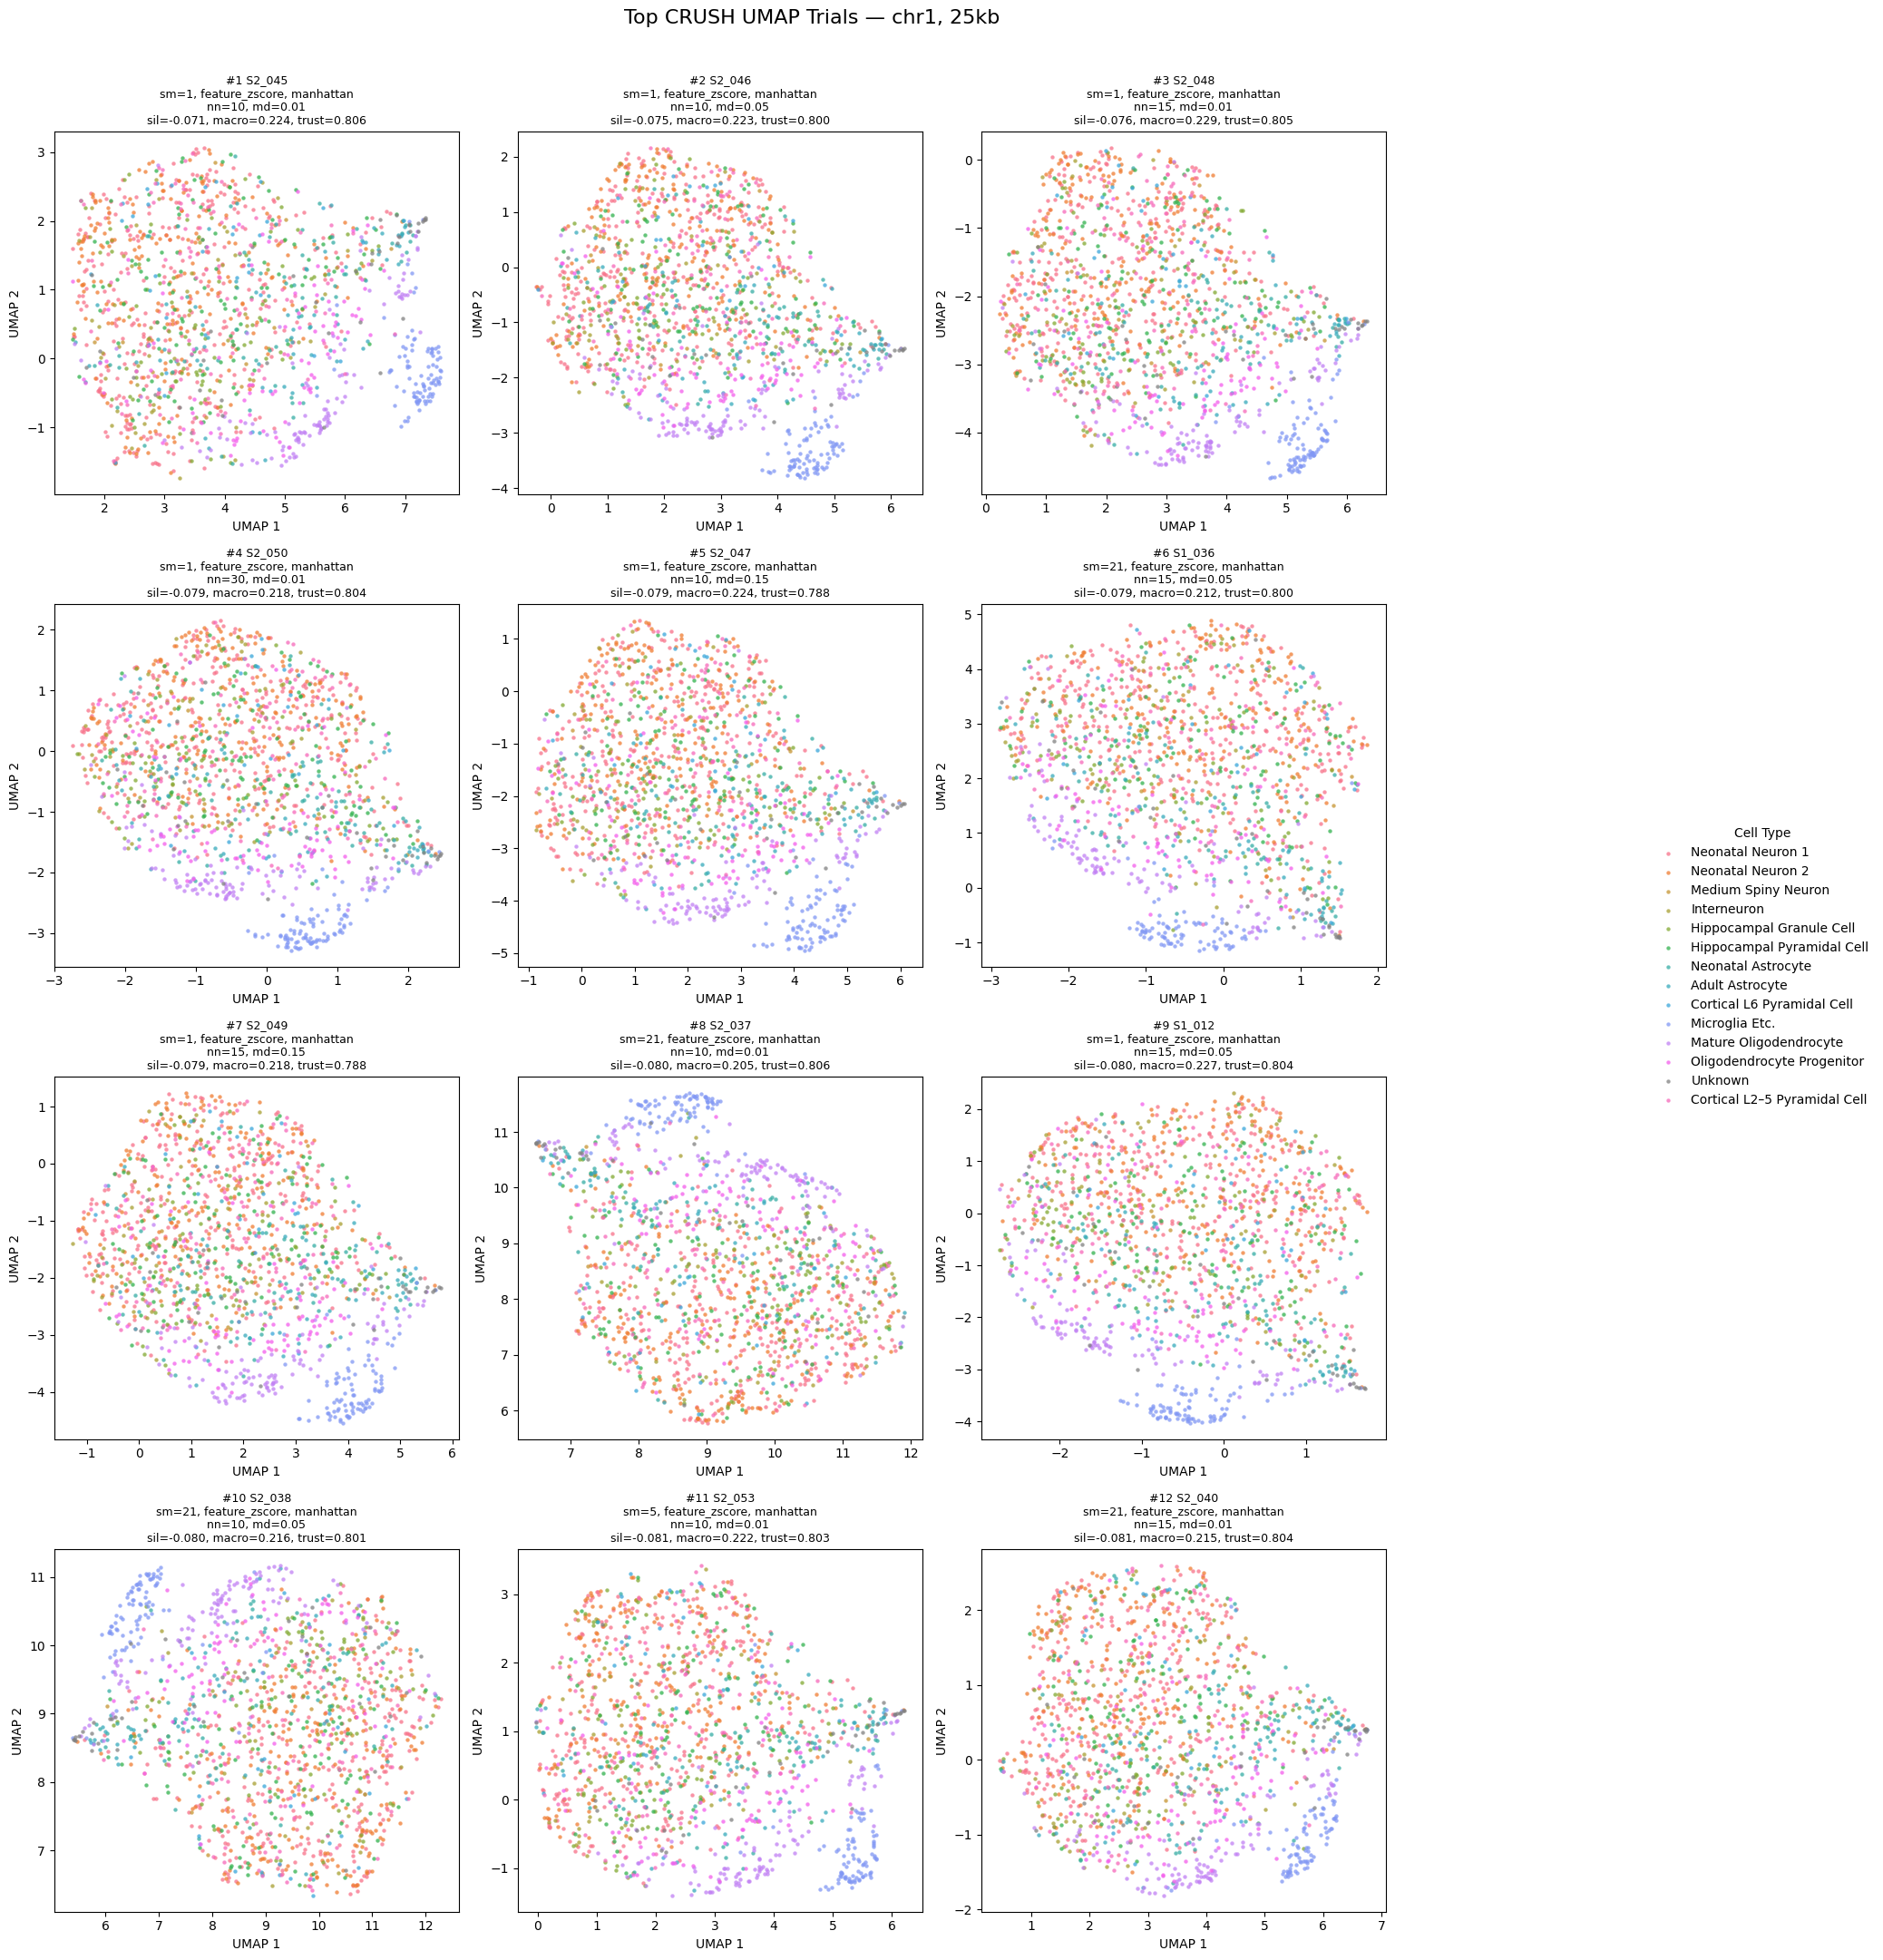


STRONGEST RESULT FOR EACH DISTANCE METRIC

     metric trial_id  smoothing_window transformation  n_neighbors  min_dist  silhouette  macro_knn_purity  trustworthiness
  manhattan   S2_045                 1 feature_zscore           10      0.01   -0.071270          0.224087         0.805972
  euclidean   S1_021                 5 feature_zscore           15      0.05   -0.094587          0.212892         0.820624
     cosine   S1_022                 5 feature_zscore           15      0.05   -0.102828          0.223704         0.833035
correlation   S1_007                 1    cell_zscore           15      0.05   -0.112595          0.218271         0.866253

BENCHMARK COMPLETE

Usable cells: 1482
Excluded all-NA cells: 472

Total UMAP trials: 60

Stage-1 results:
stage1_screening_results.csv

All ranked trials:
all_umap_trials_ranked.csv

Top UMAP panel:
TOP_UMAP_TRIALS.png

Top coordinates:
TOP_S2_045_UMAP_coordinates.csv

Best trial per metric:
best_trial_per_distance_metric.csv

QC:
i

In [10]:
import os
import re
import warnings
import unicodedata

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

import umap.umap_ as umap

from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.neighbors import NearestNeighbors
from sklearn.manifold import trustworthiness


warnings.filterwarnings("ignore")


CHROMOSOME = "1"

RESOLUTION_BP = 25000


KNN_NEIGHBORS = 10


MAX_BIN_MISSINGNESS = 0.30


VARIABLE_BIN_FRACTION = 0.50


PCA_N_COMPONENTS = 30


SMOOTHING_WINDOWS = [
    1,
    5,
    21
]


TRANSFORMATIONS = [
    "none",
    "cell_zscore",
    "feature_zscore"
]


UMAP_METRICS = [
    "euclidean",
    "cosine",
    "correlation",
    "manhattan"
]


SCREEN_N_NEIGHBORS = 15

SCREEN_MIN_DIST = 0.05


TOP_SCREEN_CONFIGS_TO_REFINE = 3


REFINE_N_NEIGHBORS = [
    10,
    15,
    30
]


REFINE_MIN_DIST = [
    0.01,
    0.05,
    0.15
]


RANDOM_STATE = 42


SAVE_EVERY_TRIAL_PLOT = True

TOP_N_PANEL = 12


RESOLUTION_LABELS = {

    25000: "25kb",

    50000: "50kb",

    100000: "100kb",

}


if RESOLUTION_BP not in RESOLUTION_LABELS:

    raise ValueError(
        f"Unsupported resolution: {RESOLUTION_BP}"
    )


RESOLUTION = RESOLUTION_LABELS[
    RESOLUTION_BP
]


CHROMOSOME = str(
    CHROMOSOME
).strip()


if CHROMOSOME.lower().startswith("chr"):

    CHROMOSOME = CHROMOSOME[3:]


BASE_DIR = (

    "GIscores_vs_Eigen/"
    "OnepunchMan/Published/redo_DipC_RUST/"
    "hippo_cortex"

)


matrix_file = os.path.join(

    BASE_DIR,

    "crush",

    f"combined_chr{CHROMOSOME}",

    f"hippo_cortex_{RESOLUTION}_chr{CHROMOSOME}.txt"

)


metadata_file = os.path.join(

    BASE_DIR,

    "metadata.cells_contacts_100k.txt"

)


output_dir = os.path.join(

    BASE_DIR,

    "analysis",

    "umap_trials",

    f"chr{CHROMOSOME}_{RESOLUTION}"

)


plots_dir = os.path.join(
    output_dir,
    "trial_plots"
)


os.makedirs(
    output_dir,
    exist_ok=True
)


os.makedirs(
    plots_dir,
    exist_ok=True
)


screen_results_file = os.path.join(

    output_dir,

    "stage1_screening_results.csv"

)


all_results_file = os.path.join(

    output_dir,

    "all_umap_trials_ranked.csv"

)


qc_file = os.path.join(

    output_dir,

    "input_QC.txt"

)


top_panel_file = os.path.join(

    output_dir,

    "TOP_UMAP_TRIALS.png"

)


BASE_CELL_TYPE_ORDER = [

    "Neonatal Neuron 1",

    "Neonatal Neuron 2",

    "Medium Spiny Neuron",

    "Interneuron",

    "Hippocampal Granule Cell",

    "Hippocampal Pyramidal Cell",

    "Cortical L2-L5 Pyramidal Cell",

    "Neonatal Astrocyte",

    "Adult Astrocyte",

    "Cortical L6 Pyramidal Cell",

    "Microglia Etc.",

    "Mature Oligodendrocyte",

    "Oligodendrocyte Progenitor",

    "Unknown",
]


if not os.path.isfile(
    matrix_file
):

    raise FileNotFoundError(
        matrix_file
    )


if not os.path.isfile(
    metadata_file
):

    raise FileNotFoundError(
        metadata_file
    )


print()
print("============================================================")
print("CRUSH UMAP BENCHMARK")
print("============================================================")

print()
print(
    "Chromosome:",
    f"chr{CHROMOSOME}"
)

print(
    "Resolution:",
    RESOLUTION
)

print()
print(
    "Matrix:"
)

print(
    matrix_file
)

print()
print(
    "Output:"
)

print(
    output_dir
)

print()
print("============================================================")


labels = pd.read_csv(

    metadata_file,

    header=None,

    sep="\t",

    usecols=[0, 1],

    names=[
        "UniqueID",
        "CellType"
    ],

    dtype=str

)


labels = labels[
    labels["UniqueID"].notna()
].copy()


labels["UniqueID"] = (

    labels["UniqueID"]
    .astype(str)
    .str.strip()

)


labels = labels[
    labels["UniqueID"] != ""
].copy()


labels = labels.reset_index(
    drop=True
)


def clean_cell_type(
    value
):

    if pd.isna(
        value
    ):

        return "Unknown"


    value = unicodedata.normalize(

        "NFKC",

        str(value)

    )


    value = re.sub(

        r"\s+",

        " ",

        value

    ).strip()


    if value.casefold() in {

        "",
        "na",
        "n/a",
        "nan",
        "none",
        "null",
        "unknown",

    }:

        return "Unknown"


    return value


labels["CellType"] = (

    labels["CellType"]
    .apply(
        clean_cell_type
    )

)


canonical_lookup = {

    x.casefold(): x

    for x in BASE_CELL_TYPE_ORDER

}


labels["CellType"] = labels[
    "CellType"
].apply(

    lambda x:
    canonical_lookup.get(
        x.casefold(),
        x
    )

)


def infer_region(
    cell_id
):

    x = str(
        cell_id
    ).lower()


    if x.startswith(
        "cortex-"
    ):

        return "Cortex"


    if x.startswith(
        "hippocampus-"
    ):

        return "Hippocampus"


    return "Unknown Region"


labels["Region"] = labels[
    "UniqueID"
].apply(
    infer_region
)


observed_order = (

    labels[
        "CellType"
    ]
    .drop_duplicates()
    .tolist()

)


extra_types = [

    x

    for x in observed_order

    if x not in BASE_CELL_TYPE_ORDER

]


CELL_TYPE_ORDER = (

    BASE_CELL_TYPE_ORDER

    +

    extra_types

)


CELL_TYPE_TO_CODE = {

    x: i

    for i, x
    in enumerate(
        CELL_TYPE_ORDER
    )

}


labels[
    "CellTypeCode"
] = (

    labels[
        "CellType"
    ]
    .map(
        CELL_TYPE_TO_CODE
    )
    .astype(int)

)


non_unknown_types = [

    x

    for x in CELL_TYPE_ORDER

    if x != "Unknown"

]


palette = sns.color_palette(

    "husl",

    n_colors=len(
        non_unknown_types
    )

)


CELL_TYPE_COLORS = dict(

    zip(
        non_unknown_types,
        palette
    )

)


CELL_TYPE_COLORS[
    "Unknown"
] = "gray"


raw_matrix = pd.read_csv(

    matrix_file,

    header=None,

    sep="\t",

    na_values=[
        "NA",
        "NaN",
        "nan",
        ""
    ],

    low_memory=False

)


bin_starts = (

    raw_matrix
    .iloc[:, 0]
    .copy()

)


score_matrix = (

    raw_matrix
    .iloc[:, 1:]
    .apply(
        pd.to_numeric,
        errors="coerce"
    )

)


X_original = (

    score_matrix
    .transpose()
    .reset_index(
        drop=True
    )

)


labels_original = labels.copy()


print()
print(
    "Metadata cells:",
    len(
        labels_original
    )
)

print(
    "Matrix cells  :",
    len(
        X_original
    )
)


if len(
    X_original
) != len(
    labels_original
):

    raise ValueError(

        "Matrix / metadata cell count mismatch."

    )


all_na_cells = (

    X_original
    .isna()
    .all(
        axis=1
    )

)


n_all_na_cells = int(

    all_na_cells.sum()

)


keep_cells = (
    ~all_na_cells
)


X = (

    X_original
    .loc[
        keep_cells
    ]
    .reset_index(
        drop=True
    )

)


labels_use = (

    labels_original
    .loc[
        keep_cells
    ]
    .reset_index(
        drop=True
    )

)


print(
    "All-NA cells  :",
    n_all_na_cells
)

print(
    "Usable cells  :",
    len(X)
)


bin_missing_fraction = (

    X
    .isna()
    .mean(
        axis=0
    )

)


keep_bins_missingness = (

    bin_missing_fraction

    <=

    MAX_BIN_MISSINGNESS

)


n_bins_before = X.shape[1]


X = (

    X.loc[
        :,
        keep_bins_missingness
    ]
    .copy()

)


n_bins_after_missingness = X.shape[1]


print()
print(
    "Bins before missingness filter:",
    n_bins_before
)

print(
    "Bins after missingness filter :",
    n_bins_after_missingness
)


if X.shape[1] == 0:

    raise ValueError(

        "No bins remain after missingness filtering."

    )


actual_knn = min(

    KNN_NEIGHBORS,

    len(X) - 1

)


imputer = KNNImputer(

    n_neighbors=actual_knn,

    weights="distance"

)


X_imputed = imputer.fit_transform(
    X
)


if not np.isfinite(
    X_imputed
).all():

    raise ValueError(

        "Non-finite values after KNN imputation."

    )


print()
print(
    "KNN neighbors:",
    actual_knn
)

print(
    "Imputed shape:",
    X_imputed.shape
)


def correlation_to_consensus(
    X
):

    consensus = np.median(
        X,
        axis=0
    )


    consensus_centered = (

        consensus

        -

        consensus.mean()

    )


    consensus_norm = np.linalg.norm(
        consensus_centered
    )


    X_centered = (

        X

        -

        X.mean(
            axis=1,
            keepdims=True
        )

    )


    row_norm = np.linalg.norm(

        X_centered,

        axis=1

    )


    denominator = (

        row_norm

        *

        consensus_norm

    )


    corr = np.divide(

        X_centered
        @
        consensus_centered,

        denominator,

        out=np.zeros(
            X.shape[0]
        ),

        where=denominator != 0

    )


    return corr


consensus_corr = correlation_to_consensus(
    X_imputed
)


median_consensus_corr = float(

    np.median(
        consensus_corr
    )

)


negative_corr_fraction = float(

    np.mean(
        consensus_corr < 0
    )

)


strong_negative_fraction = float(

    np.mean(
        consensus_corr < -0.25
    )

)


print()
print("============================================================")
print("SIGN / ORIENTATION DIAGNOSTIC")
print("============================================================")

print()

print(
    "Median corr to consensus:",
    round(
        median_consensus_corr,
        4
    )
)

print(
    "Fraction corr < 0:",
    round(
        negative_corr_fraction,
        4
    )
)

print(
    "Fraction corr < -0.25:",
    round(
        strong_negative_fraction,
        4
    )
)


with open(
    qc_file,
    "w"
) as handle:

    handle.write(
        f"Chromosome\tchr{CHROMOSOME}\n"
    )

    handle.write(
        f"Resolution\t{RESOLUTION}\n"
    )

    handle.write(
        f"MetadataCells\t{len(labels_original)}\n"
    )

    handle.write(
        f"AllNACells\t{n_all_na_cells}\n"
    )

    handle.write(
        f"UsableCells\t{len(labels_use)}\n"
    )

    handle.write(
        f"BinsBeforeFilter\t{n_bins_before}\n"
    )

    handle.write(
        f"BinsAfterMissingnessFilter\t{n_bins_after_missingness}\n"
    )

    handle.write(
        f"MedianConsensusCorrelation\t{median_consensus_corr}\n"
    )

    handle.write(
        f"NegativeConsensusCorrelationFraction\t{negative_corr_fraction}\n"
    )

    handle.write(
        f"StrongNegativeConsensusCorrelationFraction\t{strong_negative_fraction}\n"
    )


def smooth_profiles(
    X,
    window
):

    if window <= 1:

        return X.copy()


    smoothed = (

        pd.DataFrame(
            X
        )
        .T
        .rolling(

            window=window,

            center=True,

            min_periods=1

        )
        .mean()
        .T
        .to_numpy()

    )


    return smoothed


def select_variable_bins(
    X,
    fraction
):

    variance = np.var(
        X,
        axis=0
    )


    informative = (

        variance
        >
        1e-12

    )


    X2 = X[
        :,
        informative
    ]


    variance2 = variance[
        informative
    ]


    if X2.shape[1] == 0:

        raise ValueError(

            "No variable bins remain."

        )


    if fraction >= 1.0:

        return X2


    n_keep = max(

        2,

        int(
            np.ceil(
                X2.shape[1]
                *
                fraction
            )
        )

    )


    n_keep = min(

        n_keep,

        X2.shape[1]

    )


    top_idx = np.argsort(
        variance2
    )[
        -n_keep:
    ]


    top_idx = np.sort(
        top_idx
    )


    return X2[
        :,
        top_idx
    ]


def transform_profiles(
    X,
    method
):


    if method == "none":

        return X.copy()


    if method == "cell_zscore":

        row_mean = X.mean(
            axis=1,
            keepdims=True
        )


        row_std = X.std(
            axis=1,
            keepdims=True
        )


        row_std[
            row_std < 1e-12
        ] = 1.0


        return (

            X
            -
            row_mean

        ) / row_std


    if method == "feature_zscore":

        scaler = StandardScaler()


        return scaler.fit_transform(
            X
        )


    raise ValueError(

        f"Unknown transformation: {method}"

    )


representation_cache = {}


def build_representation(
    smoothing_window,
    transformation
):

    key = (
        smoothing_window,
        transformation
    )


    if key in representation_cache:

        return representation_cache[
            key
        ]


    X_work = smooth_profiles(

        X_imputed,

        smoothing_window

    )


    X_work = select_variable_bins(

        X_work,

        VARIABLE_BIN_FRACTION

    )


    n_features_selected = (
        X_work.shape[1]
    )


    X_work = transform_profiles(

        X_work,

        transformation

    )


    n_components = min(

        PCA_N_COMPONENTS,

        X_work.shape[0] - 1,

        X_work.shape[1]

    )


    pca = PCA(

        n_components=n_components,

        random_state=RANDOM_STATE

    )


    X_pca = pca.fit_transform(
        X_work
    )


    variance_explained = float(

        pca.explained_variance_ratio_
        .sum()

    )


    result = {

        "X_pca":
        X_pca,

        "n_features":
        n_features_selected,

        "pca_components":
        n_components,

        "pca_variance":
        variance_explained,

    }


    representation_cache[
        key
    ] = result


    return result


y_all = (

    labels_use[
        "CellType"
    ]
    .astype(str)
    .to_numpy()

)


known_mask = (

    y_all
    !=
    "Unknown"

)


def calculate_knn_purity(
    embedding,
    labels,
    k=10
):

    labels = np.asarray(
        labels
    )


    if len(
        embedding
    ) < 3:

        return (
            np.nan,
            np.nan
        )


    actual_k = min(

        k,

        len(
            embedding
        ) - 1

    )


    nn = NearestNeighbors(

        n_neighbors=actual_k + 1

    )


    nn.fit(
        embedding
    )


    indices = nn.kneighbors(
        embedding,
        return_distance=False
    )


    neighbors = indices[
        :,
        1:
    ]


    purity_per_cell = (

        labels[
            neighbors
        ]

        ==

        labels[
            :,
            None
        ]

    ).mean(
        axis=1
    )


    overall = float(

        purity_per_cell.mean()

    )


    class_scores = []


    for class_name in np.unique(
        labels
    ):

        mask = (
            labels
            ==
            class_name
        )


        class_scores.append(

            purity_per_cell[
                mask
            ].mean()

        )


    macro = float(

        np.mean(
            class_scores
        )

    )


    return (
        overall,
        macro
    )


def run_umap_trial(

    X_rep,

    metric,

    n_neighbors,

    min_dist

):

    reducer = umap.UMAP(

        n_neighbors=n_neighbors,

        min_dist=min_dist,

        metric=metric,

        n_components=2,

        random_state=RANDOM_STATE,

        low_memory=True

    )


    embedding = reducer.fit_transform(
        X_rep
    )


    return embedding


def score_embedding(

    X_rep,

    embedding

):

    embedding_known = embedding[
        known_mask
    ]


    labels_known = y_all[
        known_mask
    ]


    if len(
        np.unique(
            labels_known
        )
    ) > 1:

        silhouette = float(

            silhouette_score(

                embedding_known,

                labels_known,

                metric="euclidean"

            )

        )

    else:

        silhouette = np.nan


    purity, macro_purity = (
        calculate_knn_purity(

            embedding_known,

            labels_known,

            k=10

        )
    )


    trust_k = min(

        10,

        X_rep.shape[0] - 1

    )


    trust = float(

        trustworthiness(

            X_rep,

            embedding,

            n_neighbors=trust_k

        )

    )


    return {

        "silhouette":
        silhouette,

        "knn_purity":
        purity,

        "macro_knn_purity":
        macro_purity,

        "trustworthiness":
        trust,

    }


def save_trial_plot(

    embedding,

    title,

    output_path

):

    fig, ax = plt.subplots(

        figsize=(
            10,
            8
        )

    )


    for cell_type in CELL_TYPE_ORDER:

        mask = (

            y_all
            ==
            cell_type

        )


        if not mask.any():

            continue


        ax.scatter(

            embedding[
                mask,
                0
            ],

            embedding[
                mask,
                1
            ],

            s=18,

            alpha=0.80,

            linewidths=0,

            color=CELL_TYPE_COLORS[
                cell_type
            ],

            label=cell_type

        )


    ax.set_title(

        title,

        fontsize=11

    )


    ax.set_xlabel(
        "UMAP 1"
    )


    ax.set_ylabel(
        "UMAP 2"
    )


    ax.legend(

        title="Cell Type",

        bbox_to_anchor=(
            1.02,
            1
        ),

        loc="upper left",

        frameon=False,

        fontsize=8

    )


    plt.tight_layout()


    fig.savefig(

        output_path,

        dpi=180,

        bbox_inches="tight"

    )


    plt.close(
        fig
    )


results = []

embeddings = {}

trial_counter = 0


print()
print("============================================================")
print("STAGE 1 — SCREENING")
print("============================================================")


for smoothing_window in SMOOTHING_WINDOWS:

    for transformation in TRANSFORMATIONS:

        rep = build_representation(

            smoothing_window,

            transformation

        )


        X_rep = rep[
            "X_pca"
        ]


        for metric in UMAP_METRICS:

            trial_counter += 1


            trial_id = (

                f"S1_{trial_counter:03d}"

            )


            print()

            print(
                trial_id,
                "| smooth",
                smoothing_window,
                "|",
                transformation,
                "|",
                metric
            )


            embedding = run_umap_trial(

                X_rep,

                metric,

                SCREEN_N_NEIGHBORS,

                SCREEN_MIN_DIST

            )


            scores = score_embedding(

                X_rep,

                embedding

            )


            record = {

                "trial_id":
                trial_id,

                "stage":
                "screen",

                "chromosome":
                CHROMOSOME,

                "resolution":
                RESOLUTION,

                "smoothing_window":
                smoothing_window,

                "transformation":
                transformation,

                "metric":
                metric,

                "n_neighbors":
                SCREEN_N_NEIGHBORS,

                "min_dist":
                SCREEN_MIN_DIST,

                "variable_bin_fraction":
                VARIABLE_BIN_FRACTION,

                "selected_features":
                rep[
                    "n_features"
                ],

                "pca_components":
                rep[
                    "pca_components"
                ],

                "pca_variance_explained":
                rep[
                    "pca_variance"
                ],

                **scores

            }


            results.append(
                record
            )


            embeddings[
                trial_id
            ] = {

                "embedding":
                embedding,

                "X_rep":
                X_rep,

                "record":
                record

            }


            print(

                "   silhouette =",
                round(
                    scores[
                        "silhouette"
                    ],
                    4
                ),

                "| macro purity =",
                round(
                    scores[
                        "macro_knn_purity"
                    ],
                    4
                ),

                "| trust =",
                round(
                    scores[
                        "trustworthiness"
                    ],
                    4
                )

            )


            if SAVE_EVERY_TRIAL_PLOT:

                filename = (

                    f"{trial_id}"
                    f"_sm{str(smoothing_window)}"
                    f"_{transformation}"
                    f"_{metric}"
                    f".png"

                )


                title = (

                    f"{trial_id} | "
                    f"smooth={smoothing_window}, "
                    f"{transformation}, "
                    f"{metric}\n"
                    f"sil={scores['silhouette']:.3f}, "
                    f"macro-purity={scores['macro_knn_purity']:.3f}, "
                    f"trust={scores['trustworthiness']:.3f}"

                )


                save_trial_plot(

                    embedding,

                    title,

                    os.path.join(
                        plots_dir,
                        filename
                    )

                )


screen_df = pd.DataFrame(
    results
)


screen_df = screen_df.sort_values(

    by=[
        "silhouette",
        "macro_knn_purity",
        "trustworthiness"
    ],

    ascending=[
        False,
        False,
        False
    ]

).reset_index(
    drop=True
)


screen_df.to_csv(

    screen_results_file,

    index=False

)


print()
print("============================================================")
print("TOP SCREENING RESULTS")
print("============================================================")

print()


print(

    screen_df[
        [
            "trial_id",
            "smoothing_window",
            "transformation",
            "metric",
            "silhouette",
            "macro_knn_purity",
            "knn_purity",
            "trustworthiness",
            "pca_variance_explained"
        ]
    ]
    .head(
        15
    )
    .to_string(
        index=False
    )

)


top_screen = (

    screen_df
    .head(
        TOP_SCREEN_CONFIGS_TO_REFINE
    )
    .copy()

)


print()
print("============================================================")
print("STAGE 2 — PARAMETER REFINEMENT")
print("============================================================")


for _, config in top_screen.iterrows():

    smoothing_window = int(
        config["smoothing_window"]
    )

    transformation = config[
        "transformation"
    ]

    metric = config[
        "metric"
    ]


    rep = build_representation(
        smoothing_window,
        transformation
    )

    X_rep = rep[
        "X_pca"
    ]


    for n_neighbors in REFINE_N_NEIGHBORS:

        for min_dist in REFINE_MIN_DIST:


            if (
                n_neighbors == SCREEN_N_NEIGHBORS
                and
                abs(min_dist - SCREEN_MIN_DIST) < 1e-12
            ):
                continue


            trial_counter += 1

            trial_id = f"S2_{trial_counter:03d}"


            print()

            print(
                trial_id,
                "| smooth",
                smoothing_window,
                "|",
                transformation,
                "|",
                metric,
                "| nn",
                n_neighbors,
                "| md",
                min_dist
            )


            embedding = run_umap_trial(
                X_rep,
                metric,
                n_neighbors,
                min_dist
            )


            scores = score_embedding(
                X_rep,
                embedding
            )


            record = {

                "trial_id":
                    trial_id,

                "stage":
                    "refine",

                "chromosome":
                    CHROMOSOME,

                "resolution":
                    RESOLUTION,

                "smoothing_window":
                    smoothing_window,

                "transformation":
                    transformation,

                "metric":
                    metric,

                "n_neighbors":
                    n_neighbors,

                "min_dist":
                    min_dist,

                "variable_bin_fraction":
                    VARIABLE_BIN_FRACTION,

                "selected_features":
                    rep["n_features"],

                "pca_components":
                    rep["pca_components"],

                "pca_variance_explained":
                    rep["pca_variance"],

                **scores
            }


            results.append(
                record
            )


            embeddings[
                trial_id
            ] = {

                "embedding":
                    embedding,

                "X_rep":
                    X_rep,

                "record":
                    record
            }


            print(
                "   silhouette =",
                round(
                    scores["silhouette"],
                    4
                ),
                "| macro purity =",
                round(
                    scores["macro_knn_purity"],
                    4
                ),
                "| trust =",
                round(
                    scores["trustworthiness"],
                    4
                )
            )


            if SAVE_EVERY_TRIAL_PLOT:

                filename = (
                    f"{trial_id}"
                    f"_sm{smoothing_window}"
                    f"_{transformation}"
                    f"_{metric}"
                    f"_nn{n_neighbors}"
                    f"_md{str(min_dist).replace('.', 'p')}"
                    f".png"
                )


                title = (
                    f"{trial_id} | "
                    f"sm={smoothing_window}, "
                    f"{transformation}, "
                    f"{metric}, "
                    f"nn={n_neighbors}, "
                    f"md={min_dist}\n"
                    f"sil={scores['silhouette']:.3f}, "
                    f"macro-purity={scores['macro_knn_purity']:.3f}, "
                    f"trust={scores['trustworthiness']:.3f}"
                )


                save_trial_plot(
                    embedding,
                    title,
                    os.path.join(
                        plots_dir,
                        filename
                    )
                )

results_df = pd.DataFrame(
    results
)


results_df = results_df.sort_values(

    by=[
        "silhouette",
        "macro_knn_purity",
        "trustworthiness"
    ],

    ascending=[
        False,
        False,
        False
    ]

).reset_index(
    drop=True
)


results_df[
    "rank"
] = (

    np.arange(
        len(
            results_df
        )
    )

    +

    1

)


columns = [

    "rank",

    *[
        x
        for x in results_df.columns
        if x != "rank"
    ]

]


results_df = results_df[
    columns
]


results_df.to_csv(

    all_results_file,

    index=False

)


print()
print("============================================================")
print("FINAL RANKING")
print("============================================================")

print()


print(

    results_df[
        [
            "rank",
            "trial_id",
            "stage",
            "smoothing_window",
            "transformation",
            "metric",
            "n_neighbors",
            "min_dist",
            "silhouette",
            "macro_knn_purity",
            "knn_purity",
            "trustworthiness",
            "pca_variance_explained"
        ]
    ]
    .head(
        20
    )
    .to_string(
        index=False
    )

)


top_trial_id = results_df.iloc[
    0
][
    "trial_id"
]


top_embedding = embeddings[
    top_trial_id
][
    "embedding"
]


top_record = embeddings[
    top_trial_id
][
    "record"
]


top_coordinates = labels_use[
    [
        "UniqueID",
        "Region",
        "CellType",
        "CellTypeCode"
    ]
].copy()


top_coordinates[
    "UMAP_1"
] = top_embedding[
    :,
    0
]


top_coordinates[
    "UMAP_2"
] = top_embedding[
    :,
    1
]


top_coordinates_file = os.path.join(

    output_dir,

    (
        f"TOP_{top_trial_id}_"
        f"UMAP_coordinates.csv"
    )

)


top_coordinates.to_csv(

    top_coordinates_file,

    index=False

)


n_panel = min(

    TOP_N_PANEL,

    len(
        results_df
    )

)


ncols = 3

nrows = int(

    np.ceil(
        n_panel
        /
        ncols
    )

)


fig, axes = plt.subplots(

    nrows,

    ncols,

    figsize=(
        18,
        5.5
        *
        nrows
    )

)


axes = np.array(
    axes
).reshape(
    -1
)


for panel_index in range(
    n_panel
):

    row = results_df.iloc[
        panel_index
    ]


    trial_id = row[
        "trial_id"
    ]


    embedding = embeddings[
        trial_id
    ][
        "embedding"
    ]


    ax = axes[
        panel_index
    ]


    for cell_type in CELL_TYPE_ORDER:

        mask = (

            y_all
            ==
            cell_type

        )


        if not mask.any():

            continue


        ax.scatter(

            embedding[
                mask,
                0
            ],

            embedding[
                mask,
                1
            ],

            s=10,

            alpha=0.75,

            linewidths=0,

            color=CELL_TYPE_COLORS[
                cell_type
            ],

            label=cell_type

        )


    ax.set_title(

        (
            f"#{int(row['rank'])} {trial_id}\n"
            f"sm={int(row['smoothing_window'])}, "
            f"{row['transformation']}, "
            f"{row['metric']}\n"
            f"nn={int(row['n_neighbors'])}, "
            f"md={row['min_dist']}\n"
            f"sil={row['silhouette']:.3f}, "
            f"macro={row['macro_knn_purity']:.3f}, "
            f"trust={row['trustworthiness']:.3f}"
        ),

        fontsize=9

    )


    ax.set_xlabel(
        "UMAP 1"
    )


    ax.set_ylabel(
        "UMAP 2"
    )


for panel_index in range(

    n_panel,

    len(
        axes
    )

):

    axes[
        panel_index
    ].axis(
        "off"
    )


handles, legend_labels = axes[
    0
].get_legend_handles_labels()


fig.legend(

    handles,

    legend_labels,

    title="Cell Type",

    bbox_to_anchor=(
        1.01,
        0.5
    ),

    loc="center left",

    frameon=False

)


fig.suptitle(

    (
        f"Top CRUSH UMAP Trials — "
        f"chr{CHROMOSOME}, {RESOLUTION}"
    ),

    fontsize=16

)


plt.tight_layout(

    rect=[
        0,
        0,
        0.86,
        0.97
    ]

)


fig.savefig(

    top_panel_file,

    dpi=220,

    bbox_inches="tight"

)


plt.show()


metric_summary = (

    results_df
    .sort_values(
        "silhouette",
        ascending=False
    )
    .groupby(
        "metric",
        as_index=False
    )
    .first()

)


metric_summary_file = os.path.join(

    output_dir,

    "best_trial_per_distance_metric.csv"

)


metric_summary.to_csv(

    metric_summary_file,

    index=False

)


print()
print("============================================================")
print("STRONGEST RESULT FOR EACH DISTANCE METRIC")
print("============================================================")

print()


print(

    metric_summary[
        [
            "metric",
            "trial_id",
            "smoothing_window",
            "transformation",
            "n_neighbors",
            "min_dist",
            "silhouette",
            "macro_knn_purity",
            "trustworthiness"
        ]
    ]
    .sort_values(
        "silhouette",
        ascending=False
    )
    .to_string(
        index=False
    )

)


print()
print("============================================================")
print("BENCHMARK COMPLETE")
print("============================================================")

print()

print(
    "Usable cells:",
    len(
        labels_use
    )
)

print(
    "Excluded all-NA cells:",
    n_all_na_cells
)

print()

print(
    "Total UMAP trials:",
    len(
        results_df
    )
)

print()

print(
    "Stage-1 results:"
)

print(
    screen_results_file
)

print()

print(
    "All ranked trials:"
)

print(
    all_results_file
)

print()

print(
    "Top UMAP panel:"
)

print(
    top_panel_file
)

print()

print(
    "Top coordinates:"
)

print(
    top_coordinates_file
)

print()

print(
    "Best trial per metric:"
)

print(
    metric_summary_file
)

print()

print(
    "QC:"
)

print(
    qc_file
)

print()

print("============================================================")

In [2]:
import os
import re
import sys
import time
import unicodedata
import warnings

import numpy as np
import pandas as pd
import umap.umap_ as umap
from scipy.spatial.distance import pdist, squareform
from sklearn.utils.extmath import randomized_svd
from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, balanced_accuracy_score
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", message=".*n_jobs value.*")


DATASET = "hippo_cortex"

ROOT = "redo_DipC_RUST"

HIPPO_ORDER = [
    "Neonatal Neuron 1", "Neonatal Neuron 2", "Medium Spiny Neuron", "Interneuron",
    "Hippocampal Granule Cell", "Hippocampal Pyramidal Cell", "Cortical L2-L5 Pyramidal Cell",
    "Neonatal Astrocyte", "Adult Astrocyte", "Cortical L6 Pyramidal Cell", "Microglia Etc.",
    "Mature Oligodendrocyte", "Oligodendrocyte Progenitor", "Unknown",
]

PRESETS = {
    "moe_retina": dict(
        matrix=f"{ROOT}/moe_retina/crush/combined_chr1/moe_retina_25kb_c1.txt",
        labels=f"{ROOT}/moe_retina/metadata_cells_mouseOLF_updated_noBulk.txt",
        out_dir=f"{ROOT}/moe_retina/analysis/empca_umap",
        tag="moe_retina_25kb_chr1",
        colors={"MOE": "tab:red", "retina": "tab:blue"},
        order=["MOE", "retina"],
        region_prefixes=None,
    ),
    "pbmc_gm12878": dict(
        matrix=f"{ROOT}/pbmc_gm12878/crush/combined_chrX/gm12878_pbmc_25kb_cX.txt",
        labels=f"{ROOT}/pbmc_gm12878/gm12878_pbmc_Nagano_metadata_nobulk.txt",
        out_dir=f"{ROOT}/pbmc_gm12878/analysis/empca_umap",
        tag="gm12878_pbmc_25kb_chrX",
        colors={"GM12878": "tab:blue", "PBMC": "tab:orange"},
        order=["GM12878", "PBMC"],
        region_prefixes=None,
    ),
    "hippo_cortex": dict(
        matrix=f"{ROOT}/hippo_cortex/crush/combined_chr1/hippo_cortex_50kb_chr1.txt",
        labels=f"{ROOT}/hippo_cortex/metadata.cells_contacts_100k.txt",
        out_dir=f"{ROOT}/hippo_cortex/analysis/empca_umap/chr1/50kb",
        tag="hippo_cortex_50kb_chr1",
        colors={"Unknown": "lightgray"},
        order=HIPPO_ORDER,
        region_prefixes={"cortex-": "Cortex", "hippocampus-": "Hippocampus"},
    ),
}

MAX_BIN_NA = 0.5
RANK_CANDIDATES = [2, 3, 5, 10, 20, 30, 50, 80]
FIXED_RANK = None
UMAP_MIN_DIST = 0.1
SEEDS = (42, 0, 1)
NOT_SCORED = {"unknown"}
COMPARE_KNN_BASELINE = True


cfg = PRESETS[DATASET]


def clean_label(v):
    if pd.isna(v):
        return "Unknown"
    v = re.sub(r"\s+", " ", unicodedata.normalize("NFKC", str(v))).strip()
    return "Unknown" if v.casefold() in {"", "na", "n/a", "nan", "none", "null", "unknown"} else v


def read_labels(path):
    if path.lower().endswith((".ods", ".xlsx", ".xls")):
        lab = pd.read_excel(path, header=None, usecols=[0, 1], dtype=str)
    else:
        lab = pd.read_csv(path, sep="\t", header=None, usecols=[0, 1], dtype=str)
    lab.columns = ["UniqueID", "Group"]
    lab = lab[lab["UniqueID"].notna() & (lab["UniqueID"].str.strip() != "")].copy()
    lab["UniqueID"] = lab["UniqueID"].str.strip()
    lab["Group"] = lab["Group"].apply(clean_label)
    canon = {g.casefold(): g for g in cfg["order"]}
    lab["Group"] = lab["Group"].apply(lambda g: canon.get(g.casefold(), g))
    return lab.reset_index(drop=True)


def read_matrix(path):
    M = pd.read_csv(path, sep="\t", header=None, na_values=["NA", "NaN", "nan", ""], low_memory=False)
    c0 = pd.to_numeric(M[0], errors="coerce").values
    has_start = (not np.isnan(c0).any()) and np.all(np.diff(c0) > 0) and np.all(c0 % 1 == 0) and c0.max() > 1e4
    if has_start:
        start, cells = c0.astype(np.int64), M.iloc[:, 1:]
        print(f"Matrix: first column is bin start ({start[0]:,} - {start[-1]:,})")
    else:
        start, cells = np.arange(len(M), dtype=np.int64), M
        print("Matrix: no start column detected")
    V = cells.apply(pd.to_numeric, errors="coerce").values.T.astype(float)
    return V, start


def center_bins(V, clip=5):
    sd = np.nanstd(V, axis=0)
    Z = (V - np.nanmean(V, axis=0)) / np.where(sd > 0, sd, 1)
    return np.clip(Z, -clip, clip)


def em_pca(Z, rank, n_iter=300, tol=1e-4, seed=0):
    """Iterative SVD fitted to observed entries only. Returns (cell scores U*S, low-rank fit)."""
    M = ~np.isnan(Z)
    X = np.where(M, Z, 0.0)
    prev = None
    for _ in range(n_iter):
        U, s, Vt = randomized_svd(X, rank, n_oversamples=10, random_state=seed)
        L = (U * s) @ Vt
        X = np.where(M, Z, L)
        if prev is not None and np.linalg.norm(L - prev) / np.linalg.norm(L) < tol:
            break
        prev = L
    return U * s, L


def choose_rank(Z, ranks, frac=0.05, reps=2, within=0.01):
    """Label-free rank choice: hide 5% of observed values, measure prediction error."""
    rng = np.random.default_rng(0)
    obs = np.argwhere(~np.isnan(Z))
    rows = []
    for rep in range(reps):
        hide = obs[rng.random(len(obs)) < frac]
        Zt = Z.copy(); Zt[hide[:, 0], hide[:, 1]] = np.nan
        truth = Z[hide[:, 0], hide[:, 1]]
        for k in ranks:
            t = time.time()
            _, L = em_pca(Zt, k)
            rmse = float(np.sqrt(np.mean((L[hide[:, 0], hide[:, 1]] - truth) ** 2)))
            rows.append((rep, k, rmse))
            print(f"  rep {rep + 1}/{reps}  rank {k:3d}: held-out RMSE {rmse:.4f}  ({time.time() - t:.0f}s)", flush=True)
    cv = pd.DataFrame(rows, columns=["rep", "rank", "heldout_rmse"]).groupby("rank")["heldout_rmse"].agg(["mean", "std"])
    ok = cv.index[cv["mean"] <= cv["mean"].min() * (1 + within)]
    return int(min(ok)), cv


def separation(D, y, scored, k):
    """Leave-one-out kNN on the distance matrix, using only scored cells."""
    idx = np.where(scored)[0]
    Ds, ys = D[np.ix_(idx, idx)], y[idx]
    pred = []
    for i in range(len(idx)):
        d = Ds[i].copy(); d[i] = np.inf
        v, c = np.unique(ys[np.argsort(d)[:k]], return_counts=True)
        pred.append(v[np.argmax(c)])
    pred = np.array(pred)
    per_group = {g: float((pred[ys == g] == g).mean()) for g in np.unique(ys)}
    res = {"balanced_accuracy": balanced_accuracy_score(ys, pred),
           "silhouette": silhouette_score(Ds, ys, metric="precomputed") if len(np.unique(ys)) > 1 else np.nan}
    res.update({f"correct_{g}": v for g, v in per_group.items()})
    return res, pred, idx


def colors_for(groups):
    present = [g for g in cfg["order"] if g in groups] + sorted(g for g in groups if g not in cfg["order"])
    fixed = dict(cfg["colors"])
    need = [g for g in present if g not in fixed]
    fixed.update(dict(zip(need, sns.color_palette("husl", n_colors=max(len(need), 1)))))
    return present, fixed


t0 = time.time()
for name in ("matrix", "labels"):
    if not os.path.isfile(cfg[name]):
        sys.exit(f"ERROR: {name} file not found:\n  {cfg[name]}\nEdit PRESETS['{DATASET}']['{name}'].")
os.makedirs(cfg["out_dir"], exist_ok=True)
TAG, OUT = cfg["tag"], cfg["out_dir"]
print(f"Dataset: {DATASET}\nMatrix : {cfg['matrix']}\nLabels : {cfg['labels']}\nOutput : {OUT}\n")

lab = read_labels(cfg["labels"])
V, start = read_matrix(cfg["matrix"])
if len(V) != len(lab):
    sys.exit(f"ERROR: matrix has {len(V)} cell columns, metadata has {len(lab)} rows. "
             "They must match one-to-one in the same order.")

is_bulk = lab["Group"].str.casefold().str.startswith("bulk").values
all_na = np.isnan(V).all(axis=1)
drop = is_bulk | all_na
if drop.any():
    ex = lab.loc[drop].copy()
    ex["Reason"] = np.where(is_bulk[drop], "bulk column", "all values NA")
    ex.to_csv(os.path.join(OUT, f"{TAG}_excluded_cells.csv"), index=False)
    print(f"Excluded {drop.sum()} columns ({is_bulk.sum()} bulk, {(all_na & ~is_bulk).sum()} all-NA cells)")
V, lab = V[~drop], lab.loc[~drop].reset_index(drop=True)
if cfg["region_prefixes"]:
    lab["Region"] = lab["UniqueID"].str.lower().map(
        lambda s: next((r for p, r in cfg["region_prefixes"].items() if s.startswith(p)), "Unknown Region"))

n = len(V)
y = lab["Group"].values
cell_na = np.isnan(V).mean(axis=1)
print(f"Cells used: {n}  {dict(lab['Group'].value_counts())}")
print(f"Per-cell NA: median {np.median(cell_na):.3f}, max {cell_na.max():.3f}")

keep = np.isnan(V).mean(axis=0) <= MAX_BIN_NA
print(f"Bins: {V.shape[1]} -> {keep.sum()} kept (<= {MAX_BIN_NA:.0%} NA across cells)")
Z = center_bins(V[:, keep])

k_nn = int(min(15, max(5, n // 4)))
ranks = [r for r in RANK_CANDIDATES if r <= max(2, n // 3)]
print(f"Neighbours (UMAP and kNN score): {k_nn};  rank candidates: {ranks}")

if FIXED_RANK is None:
    print("\nChoosing rank without labels (slowest step)...", flush=True)
    rank, cv = choose_rank(Z, ranks)
    cv.to_csv(os.path.join(OUT, f"{TAG}_rank_cv.csv"))
    print(cv.round(4).to_string())
else:
    rank = FIXED_RANK
print(f"\nRank used: {rank}\nFitting EM-PCA...", flush=True)
scores, _ = em_pca(Z, rank)
np.save(os.path.join(OUT, f"{TAG}_empca_scores_rank{rank}.npy"), scores)
D = squareform(pdist(scores, metric="cosine"))

scored = ~pd.Series(y).str.casefold().isin(NOT_SCORED).values
metrics, pred, scored_idx = separation(D, y, scored, k_nn)
rows = [{"pipeline": f"EM-PCA rank {rank}", **metrics}]
if COMPARE_KNN_BASELINE:
    print("Scoring original KNNImputer pipeline for comparison...", flush=True)
    Xb = StandardScaler().fit_transform(KNNImputer(n_neighbors=min(5, n - 1)).fit_transform(V))
    Db = squareform(pdist(Xb, metric="cosine"))
    rows.append({"pipeline": "KNNImputer (original)", **separation(Db, y, scored, k_nn)[0]})
met = pd.DataFrame(rows)
met.insert(1, "n_cells_scored", int(scored.sum()))
met.to_csv(os.path.join(OUT, f"{TAG}_metrics.csv"), index=False)
print("\nSeparation (leave-one-out kNN; balanced accuracy averages per-group recall):")
print(met.round(3).to_string(index=False))

groupings = ["Group"] + (["Region"] if "Region" in lab else [])
embs = {s: umap.UMAP(n_neighbors=k_nn, min_dist=UMAP_MIN_DIST, metric="cosine",
                     random_state=s).fit_transform(scores) for s in SEEDS}
e0 = embs[SEEDS[0]]
out = lab.copy()
out["UMAP_1"], out["UMAP_2"], out["NA_frac"] = e0[:, 0], e0[:, 1], cell_na
out["kNN_pred"] = ""
out.loc[scored_idx, "kNN_pred"] = pred
out.to_csv(os.path.join(OUT, f"{TAG}_umap_coords.csv"), index=False)

for gcol in groupings:
    present, cmap = colors_for(set(lab[gcol]))
    many = len(present) > 4
    fig, axes = plt.subplots(1, len(SEEDS) + 1, figsize=(5.2 * (len(SEEDS) + 1), 5.2))
    for ax, s in zip(axes, SEEDS):
        e = embs[s]
        for g in present:
            m = (lab[gcol] == g).values
            ax.scatter(*e[m].T, color=cmap[g], s=10 if n > 200 else 30, alpha=0.85, linewidths=0, label=g)
        ax.set_title(f"seed {s}", fontsize=10); ax.set_xticks([]); ax.set_yticks([])
    sc = axes[-1].scatter(*e0.T, c=cell_na, cmap="viridis", s=10 if n > 200 else 30, linewidths=0)
    axes[-1].set_title(f"seed {SEEDS[0]}: per-cell NA fraction", fontsize=10)
    axes[-1].set_xticks([]); axes[-1].set_yticks([])
    plt.colorbar(sc, ax=axes[-1], fraction=0.046)
    axes[0].legend(frameon=False, fontsize=7 if many else 9, markerscale=1.5,
                   loc="upper left", bbox_to_anchor=(0, -0.02), ncol=3 if many else len(present))
    m0 = met.iloc[0]
    fig.suptitle(f"{TAG} | EM-PCA rank {rank} -> UMAP (cosine, n_neighbors {k_nn}) | coloured by {gcol}"
                 f" | balanced accuracy {m0['balanced_accuracy']:.2f}", fontsize=11)
    plt.tight_layout()
    for ext in ("png", "pdf"):
        plt.savefig(os.path.join(OUT, f"{TAG}_umap_by_{gcol}.{ext}"), dpi=200, bbox_inches="tight")
    plt.close()

print(f"\nDone in {time.time() - t0:.0f}s. Files in {OUT}")

Dataset: hippo_cortex
Matrix : hippo_cortex_50kb_chr1.txt
Labels : metadata.cells_contacts_100k.txt
Output : 50kb

Matrix: first column is bin start (3,000,000 - 195,350,000)
Excluded 474 columns (0 bulk, 474 all-NA cells)
Cells used: 1480  {'Neonatal Neuron 1': 345, 'Neonatal Neuron 2': 238, 'Hippocampal Pyramidal Cell': 121, 'Mature Oligodendrocyte': 114, 'Cortical L2–5 Pyramidal Cell': 97, 'Microglia Etc.': 93, 'Oligodendrocyte Progenitor': 91, 'Hippocampal Granule Cell': 91, 'Neonatal Astrocyte': 75, 'Adult Astrocyte': 67, 'Interneuron': 63, 'Unknown': 37, 'Cortical L6 Pyramidal Cell': 36, 'Medium Spiny Neuron': 12}
Per-cell NA: median 0.006, max 0.235
Bins: 3846 -> 3841 kept (<= 50% NA across cells)
Neighbours (UMAP and kNN score): 15;  rank candidates: [2, 3, 5, 10, 20, 30, 50, 80]

Choosing rank without labels (slowest step)...
  rep 1/2  rank   2: held-out RMSE 0.9414  (10s)
  rep 1/2  rank   3: held-out RMSE 0.9293  (6s)
  rep 1/2  rank   5: held-out RMSE 0.9071  (4s)
  rep 1/

In [ ]:
pip install scikit-learn
pip install matplotlib
pip install seaborn
pip install umap

In [ ]:
pip install umap-learn


In [1]:
import numpy as np
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import umap.umap_ as umap
%matplotlib inline

site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
sns.set(style='white', context='notebook', rc={'figure.figsize':(14,10)})

In [3]:
penguins = pd.read_csv("hippo_cortex_25kb_NAed_NostartCol.tsv", header=None, sep='\t')
penguins.head()

,0,1,2,3,4,5,6,7,8,9,...,1944,1945,1946,1947,1948,1949,1950,1951,1952,1953
0,-255.9260,41.8930,-37.2916,38.5471,22.7773,-210.9790,-133.2680,29.9398,36.4393,225.2980,...,-117.92100,-22.6679,-80.1823,-23.9098,54.0866,44.4631,-71.5461,-39.4381,-50.2881,-116.591
1,-270.5120,50.9669,-53.1360,11.8453,34.0184,-238.5770,-62.3433,29.9398,68.6251,63.9692,...,-45.85920,-50.2218,-23.9667,73.7830,79.1753,-19.3815,-105.7550,92.4598,-198.8770,NaN
2,-69.9663,52.2639,37.0049,18.6900,27.5464,-278.8830,-48.1299,25.5154,98.2838,90.8416,...,0.52283,-93.0923,-34.7483,119.3400,30.1630,-77.6714,-59.5415,39.6346,-63.9179,NaN
3,-346.9370,52.2639,29.9981,-45.9946,41.7702,-297.2950,-40.7241,25.5154,91.0409,114.8300,...,-22.85680,-15.0035,-21.1737,107.8810,38.1072,-86.2392,-39.7155,32.8402,-50.5978,NaN
4,-48.2754,76.6242,23.9597,32.3609,69.4110,-51.8203,-195.0870,206.6190,49.4877,127.2410,...,14.69460,-68.4102,-4.1249,59.3464,123.0520,-113.2240,-15.6196,4.3516,-98.8850,NaN


In [ ]:
penguins

In [19]:
penguins_50kb = pd.read_csv("hippo_cortex_50kb_NAed_noStart.tsv", header=None, sep='\t')
penguins_50kb.head()

,0,1,2,3,4,5,6,7,8,9,...,1944,1945,1946,1947,1948,1949,1950,1951,1952,1953
0,-247.9850,60.8834,-37.7868,43.7787,41.4743,-235.1660,-113.0960,36.3247,84.2973,186.291,...,-25.64820,-83.6784,-40.68630,99.2706,71.6132,-79.8342,-89.39320,29.8503,-135.5230,NaN
1,-291.7690,62.4327,36.6257,29.7875,50.9250,-282.0340,-57.3185,30.9568,132.1610,137.957,...,-23.54060,-82.5264,-44.10110,119.8910,69.0884,-70.7570,-45.56870,39.4819,-23.5103,NaN
2,-90.0055,91.5328,69.1269,48.8641,108.7660,-100.4220,-199.7340,160.3630,60.7894,165.254,...,8.69439,-76.7682,1.22308,70.9755,93.2762,-103.4530,5.67834,13.7969,-59.8434,NaN
3,-67.2007,70.9328,67.5408,55.7584,118.2800,-99.3383,-107.3540,89.8361,89.1493,156.765,...,19.70320,-65.9682,24.09330,61.3045,47.4943,23.0212,-3.42887,26.3849,-104.1510,NaN
4,-128.8880,30.2861,25.6756,42.1733,127.3970,-18.5473,-76.5865,26.5587,74.9170,166.463,...,-70.72910,49.0181,-21.83930,64.8493,160.0370,73.4002,42.40360,11.5263,78.6877,-77.4501


In [20]:
penguins_100kb = pd.read_csv("hippo_cortex_100kb_NAed_noStart.tsv", header=None, sep='\t')
penguins_100kb.head()

,0,1,2,3,4,5,6,7,8,9,...,1944,1945,1946,1947,1948,1949,1950,1951,1952,1953
0,-231.7850,79.1736,44.7259,58.2002,73.9646,-219.81100,-78.9110,46.9982,142.107,216.7270,...,-0.217591,-89.28130,-23.1650,132.7970,84.4731,-54.4210,-34.6003,40.0517,-63.1456,NaN
1,-111.4780,89.9530,64.7468,55.3800,118.4320,-105.63300,-128.9850,100.9890,104.957,194.4790,...,31.439100,-100.77500,23.7852,98.2082,89.1058,-86.1238,10.2816,22.6161,-46.6920,NaN
2,-124.3000,64.0925,44.9258,85.7055,104.8760,-35.45750,-22.8076,54.4494,104.264,202.5470,...,46.875100,-2.68488,89.4025,153.3940,86.1529,-32.0311,28.0660,58.5386,-65.8407,NaN
3,-85.7823,61.9537,53.7802,92.9980,112.1520,-6.23256,-131.5980,65.8961,183.989,115.9630,...,64.579000,75.90080,104.8370,122.8280,-153.2820,34.7791,53.9712,-18.8685,NaN,NaN
4,-79.4296,75.8931,33.9429,209.0110,94.2848,-45.18240,-122.3430,97.0342,139.953,79.7139,...,88.646300,-115.49200,98.0979,115.0510,91.4786,-137.0870,20.5767,45.4642,-90.7632,NaN


In [4]:
penguins_T = penguins.transpose()
penguins_T.head()

,0,1,2,3,4,5,6,7,8,9,...,7688,7689,7690,7691,7692,7693,7694,7695,7696,7697
0,-255.9260,-270.5120,-69.9663,-346.9370,-48.2754,-104.6300,-48.2658,-52.7328,-122.4970,-130.03900,...,-38.17910,-17.90340,-35.39080,-35.39080,-11.16270,-11.16270,-11.16270,-11.16270,-11.16270,-11.16270
1,41.8930,50.9669,52.2639,52.2639,76.6242,99.5859,59.3795,59.3795,-19.3912,23.74850,...,-12.09990,41.39590,62.43670,60.91060,48.51210,48.56270,-28.15680,-1.43746,-4.39334,-4.39334
2,-37.2916,-53.1360,37.0049,29.9981,23.9597,86.8199,57.8956,85.6160,14.4798,-4.44585,...,-12.31020,-97.18200,-39.67770,-24.57640,-62.55360,-39.81940,-31.84730,-13.22230,30.70410,30.70410
3,38.5471,11.8453,18.6900,-45.9946,32.3609,35.2378,49.5304,64.1397,24.2705,33.17810,...,18.19600,27.37810,-14.03380,13.57920,14.55590,7.44745,6.91414,20.60320,17.95760,17.95760
4,22.7773,34.0184,27.5464,41.7702,69.4110,91.0620,86.2621,129.0980,119.1960,97.18260,...,-6.29691,-2.77816,9.16478,9.16478,4.96583,4.96583,4.96583,4.96583,4.96583,4.96583


In [ ]:
penguins_T


In [21]:
penguins_50kb_T= penguins_50kb.transpose()
penguins_50kb_T.head()

,0,1,2,3,4,5,6,7,8,9,...,3839,3840,3841,3842,3843,3844,3845,3846,3847,3848
0,-247.9850,-291.7690,-90.0055,-67.2007,-128.8880,-104.6020,-82.7081,-82.7190,-93.2384,-36.0332,...,-5.37141,17.4199,21.511000,19.9148,-21.147900,-24.2443,-24.94720,-13.33560,-13.33560,-13.33560
1,60.8834,62.4327,91.5328,70.9328,30.2861,31.4686,42.4835,48.5091,65.2404,89.5405,...,-12.12680,-54.0357,-0.611266,55.2087,14.239000,23.8575,57.37020,35.29280,-1.71714,-5.24814
2,-37.7868,36.6257,69.1269,67.5408,25.6756,43.7035,35.6019,54.3851,36.6913,45.2213,...,-28.59750,-43.5094,-29.581900,-66.9704,-62.438300,-13.1988,-24.77750,-28.31040,-16.14360,37.48760
3,43.7787,29.7875,48.8641,55.7584,42.1733,84.1709,57.9469,93.9394,205.4360,258.0260,...,-34.50100,17.4857,24.200100,52.7286,31.631100,22.3667,-5.42579,24.19640,23.19390,20.21560
4,41.4743,50.9250,108.7660,118.2800,127.3970,89.1963,70.8203,100.4200,58.7934,88.4762,...,-6.79840,100.7640,68.049700,28.9179,0.533956,13.7932,11.17340,6.05419,6.05419,6.05419


In [22]:
penguins_100kb_T= penguins_100kb.transpose()
penguins_100kb_T.head()

,0,1,2,3,4,5,6,7,8,9,...,1914,1915,1916,1917,1918,1919,1920,1921,1922,1923
0,-231.7850,-111.4780,-124.3000,-85.7823,-79.4296,-33.7440,-27.2307,-44.2971,-21.0145,-27.93490,...,-8.35681,-31.4876,-46.3926,-10.119200,1.37912,-8.22915,-1.78346,-11.7809,-27.12810,-16.90870
1,79.1736,89.9530,64.0925,61.9537,75.8931,46.7480,-25.0207,63.6587,89.5581,131.22400,...,15.78830,-64.9898,-84.5134,48.048800,-25.90510,-62.06070,-37.46380,28.6965,3.83554,32.16590
2,44.7259,64.7468,44.9258,53.7802,33.9429,-10.4932,-103.6860,-51.3699,-26.5017,8.74387,...,-54.75910,-44.1846,-10.4656,-0.985917,-15.77070,-68.97180,-1.24349,-28.4929,30.87410,-6.37865
3,58.2002,55.3800,85.7055,92.9980,209.0110,157.3190,94.5239,121.3870,109.2500,174.59200,...,139.11300,19.2742,34.0258,21.651400,14.13040,4.61069,30.82630,50.4459,23.66190,32.49650
4,73.9646,118.4320,104.8760,112.1520,94.2848,93.0011,133.0640,64.0400,57.4345,67.25850,...,-67.56640,-122.5850,-160.3010,-148.361000,-25.01400,-34.99410,95.35120,27.8990,12.15820,7.81481


In [5]:
penguins_T = penguins_T.dropna()


In [ ]:
penguins = penguins.dropna()

In [23]:
penguins_50kb_T = penguins_50kb_T.dropna()

In [24]:
penguins_100kb_T = penguins_100kb_T.dropna()

In [6]:
reducer = umap.UMAP()

In [7]:
embedding = reducer.fit_transform(penguins_T)
embedding_100kb.shape

(1938, 2)

In [25]:
embedding_50kb = reducer.fit_transform(penguins_50kb_T)
embedding.shape

(1938, 2)

In [35]:
embedding_100kb = reducer.fit_transform(penguins_100kb_T)
embedding_100kb.shape

(1944, 2)

In [8]:
penguins_labels = pd.read_csv("metadata.cells_contacts_100k.txt", header=None, sep='\t')
penguins_labels.head()

,0,1
0,cortex-p001-cb_001,Neonatal Astrocyte
1,cortex-p001-cb_002,Neonatal Neuron 1
2,cortex-p001-cb_003,Neonatal Neuron 2
3,cortex-p001-cb_004,Unknown
4,cortex-p001-cb_005,Neonatal Neuron 2


In [9]:
penguins_labels.columns = ['cells', 'types']
penguins_labels.head()
penguins_labels.tail()

,cells,types
1949,hippocampus-p347-cb_181,Hippocampal Pyramidal Cell
1950,hippocampus-p347-cb_184,Interneuron
1951,hippocampus-p347-cb_187,Mature Oligodendrocyte
1952,hippocampus-p347-cb_188,Hippocampal Granule Cell
1953,hippocampus-p347-cb_191,Hippocampal Pyramidal Cell


In [40]:
tissue_to_color = {
    "Neonatal Neuron 1": 0,
    "Neonatal Neuron 2": 1,
    "Medium Spiny Neuron": 2,
    "Interneuron": 3,
    "Hippocampal Granule Cell": 4,
    "Hippocampal Pyramidal Cell": 5,
    "Cortical L2-L5 Pyramidal Cell": 6,
    "Neonatal Astrocyte": 7,
    "Adult Astrocyte": 8,
    "Cortical L6 Pyramidal Cell": 9,
    "Microglia Etc.": 10,
    "Mature Oligodendrocyte": 11,
    "Oligodendrocyte Progenitor": 12,
}

color_indices = [tissue_to_color.get(x, 13) for x in penguins_labels.types]

palette = sns.color_palette("Set1", n_colors=14)

colors = [palette[i] for i in color_indices]



In [15]:
colors = colors[:len(embedding)]

Text(0.5, 1.0, 'UMAP projection of Hippo-Cortex-25kb')

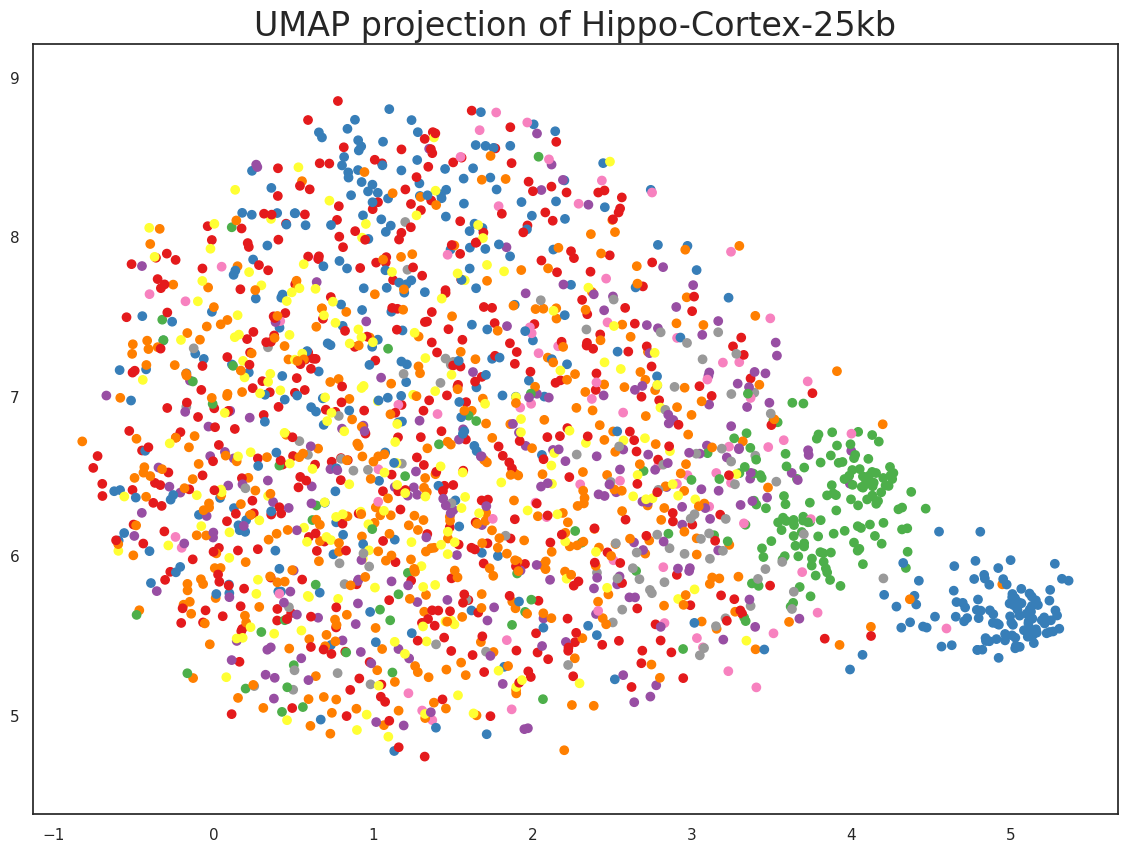

In [17]:
plt.scatter(
    embedding[:,0 ],
    embedding[:,1 ],
    alpha=1,
    c=colors)
plt.gca().set_aspect('equal', 'datalim')
plt.title('UMAP projection of Hippo-Cortex-25kb', fontsize=24)

In [ ]:
print(len(embedding[:, 0]))
print(len(embedding[:, 1]))


In [ ]:
print(len(colors))


In [27]:
colors_50kb = colors[:len(embedding_50kb)]

Text(0.5, 1.0, 'UMAP projection of Hippo-Cortex-50kb')

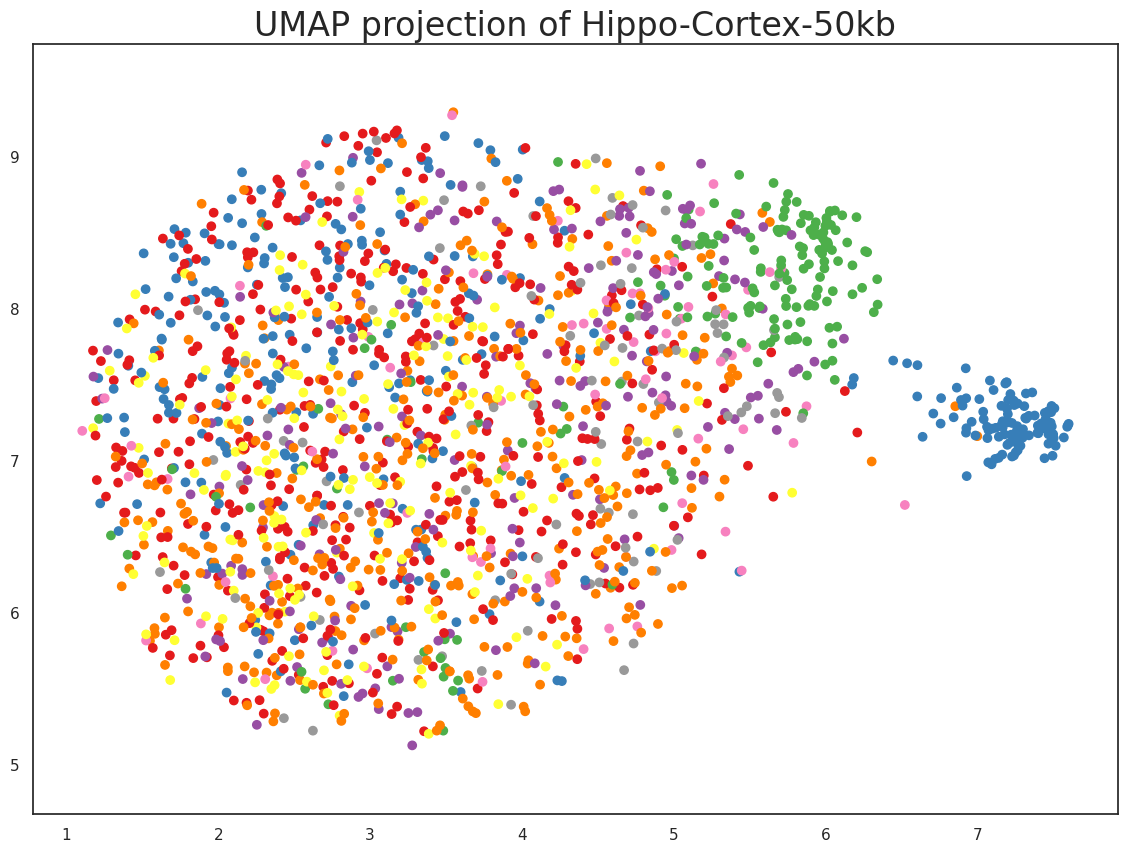

In [29]:
plt.scatter(
    embedding_50kb[:,0 ],
    embedding_50kb[:,1 ],
    alpha=1,
    c=colors_50kb)
plt.gca().set_aspect('equal', 'datalim')
plt.title('UMAP projection of Hippo-Cortex-50kb', fontsize=24)

In [36]:
colors_100kb = colors[:len(embedding_100kb)]

Text(0.5, 1.0, 'UMAP projection of Hippo-Cortex-100kb')

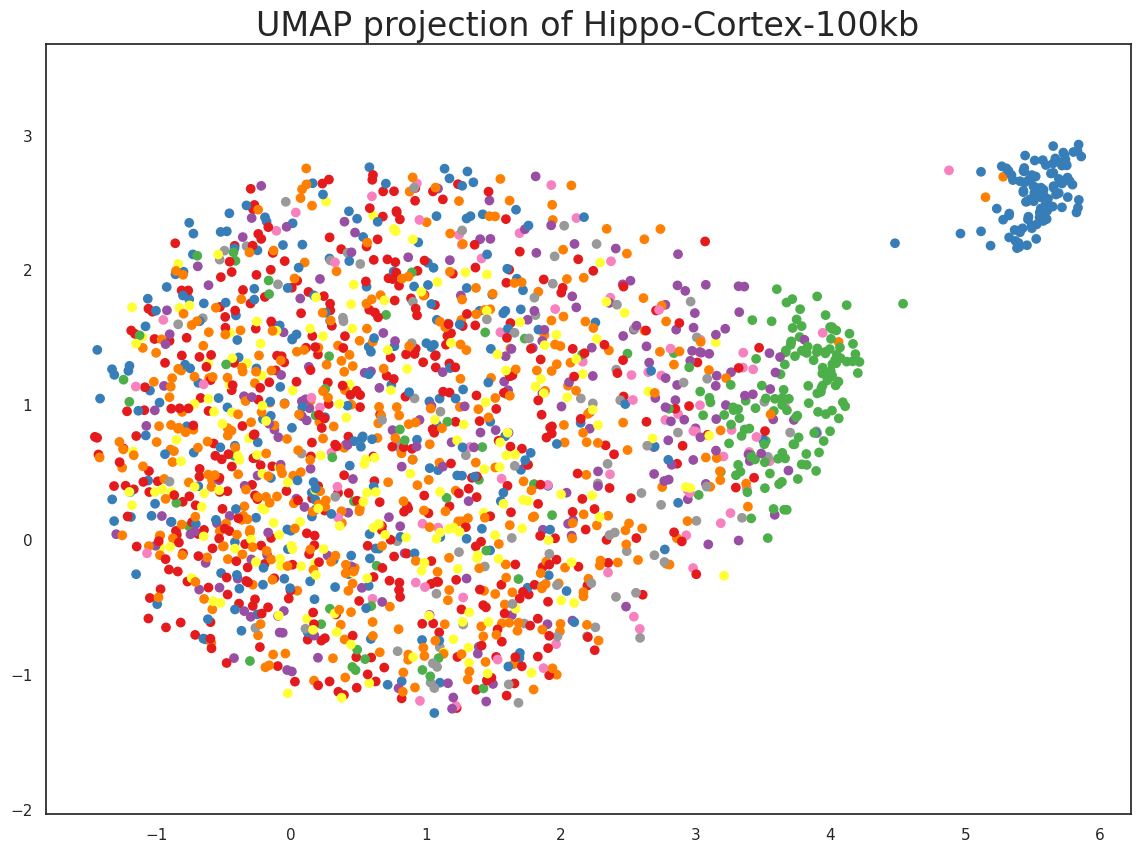

In [42]:
plt.scatter(
    embedding_100kb[:,0 ],
    embedding_100kb[:,1 ],
    alpha=1,
    c=colors[:len(embedding_100kb)])
plt.gca().set_aspect('equal', 'datalim')
plt.title('UMAP projection of Hippo-Cortex-100kb', fontsize=24)

In [ ]:
plt.scatter(
    embedding[:, 0],
    embedding[:, 1],
    alpha=1,
    s=[[x] for x in penguins_labels.annot.map({"oth":.0001, "enh":.1,"genes":.1})],
    c=[sns.color_palette()[x] for x in penguins_labels.e100.map({"B":4, "A":2 })])
plt.gca().set_aspect('equal', 'datalim')
plt.title('UMAP projection of Avocado', fontsize=24)

In [ ]:
plt.scatter(
    embedding[:, 0],
    embedding[:, 1],
    alpha=1,
    s=[[x] for x in penguins_labels.annot.map({"oth":0.0001, "enh":.1,"genes":.1})],
    c=[sns.color_palette('Set1')[x] for x in penguins_labels.combo.map({"AB":5, "AA":0,"BA":6,"BB":3 })])
plt.gca().set_aspect('equal', 'datalim')
plt.title('UMAP projection of Avocado', fontsize=24)

In [ ]:
enhancer_labels = pd.read_csv("avocado/aElabel", header=None, sep='\t')
enhancer_labels.columns = ['activity']
enhancer_labels.head()

In [ ]:
plt.scatter(
    embedding[:, 0],
    embedding[:, 1],
    alpha=1,
    s=[[x] for x in penguins_labels.annot.map({"oth":.0001, "enh":.1,"genes":.1})],
    c=[sns.color_palette()[x] for x in enhancer_labels.activity.map({"iE":7, "aE":8 })])
plt.gca().set_aspect('equal', 'datalim')
plt.title('UMAP projection of Avocado', fontsize=24)

In [ ]:
gene_labels = pd.read_csv("avocado/aGElabel", header=None, sep='\t')
gene_labels.columns = ['activity']
gene_labels.head()
plt.scatter(
    embedding[:, 0],
    embedding[:, 1],
    alpha=1,
    s=[[x] for x in penguins_labels.annot.map({"oth":.0001, "enh":.1,"genes":.1})],
    c=[sns.color_palette()[x] for x in gene_labels.activity.map({"iG":7, "aG":9, "aE":3 })])
plt.gca().set_aspect('equal', 'datalim')
plt.title('UMAP projection of Avocado', fontsize=24)

In [ ]:
plt.scatter(
    embedding[:, 0],
    embedding[:, 1],
    alpha=1,
    s=penguins[10]/40,
    c='grey')
plt.gca().set_aspect('equal', 'datalim')
plt.title('UMAP projection of Avocado', fontsize=24)

In [ ]:
trimpeng = penguins[[0,2,9,10,11,13,15,18,19]]
embedtrim = reducer.fit_transform(trimpeng)
embedtrim.shape

In [ ]:
gene_labels = pd.read_csv("avocado/aGElabel", header=None, sep='\t')
gene_labels.columns = ['activity']
gene_labels.head()
plt.scatter(
    embedtrim[:, 0],
    embedtrim[:, 1],
    alpha=1,
    s=[[x] for x in penguins_labels.annot.map({"oth":.0001, "enh":.1,"genes":.1})],
    c=[sns.color_palette()[x] for x in gene_labels.activity.map({"iG":7, "aG":9, "aE":3 })])
plt.gca().set_aspect('equal', 'datalim')
plt.title('UMAP projection of Avocado', fontsize=24)

In [ ]:
plt.scatter(
    embedtrim[:, 0],
    embedtrim[:, 1],
    alpha=1,
    s=[[x] for x in penguins_labels.annot.map({"oth":.0001, "enh":.1,"genes":.1})],
    c=[sns.color_palette()[x] for x in penguins_labels.e500.map({"A":2, "B":4})])
plt.gca().set_aspect('equal', 'datalim')
plt.title('UMAP projection of Avocado', fontsize=24)

In [ ]:
plt.scatter(
    embedtrim[:, 0],
    embedtrim[:, 1],
    alpha=1,
    s=[[x] for x in penguins_labels.annot.map({"oth":.0001, "enh":.1,"genes":.1})],
    c=[sns.color_palette()[x] for x in penguins_labels.e1.map({"B":4, "A":2})])
plt.gca().set_aspect('equal', 'datalim')
plt.title('UMAP projection of Avocado', fontsize=24)

In [ ]:
plt.scatter(
    embedtrim[:, 0],
    embedtrim[:, 1],
    alpha=1,
    s=[[x] for x in penguins_labels.annot.map({"oth":0.0001, "enh":.1,"genes":.1})],
    c=[sns.color_palette('Set1')[x] for x in penguins_labels.combo.map({"AB":5, "AA":0,"BA":6,"BB":3 })])
plt.gca().set_aspect('equal', 'datalim')
plt.title('UMAP projection of Avocado', fontsize=24)

In [ ]:
print(embedtrim[:,1])

In [ ]:
penguins_labels['vector1'] = embedtrim[:,0]
penguins_labels['vector2'] = embedtrim[:,1]

In [ ]:
penguins_labels.to_csv("umapresults", sep="\t", header=False)

In [ ]:
rslt_df = penguins[penguins_labels['annot'] != "oth"] 
rslt_lb = penguins_labels[penguins_labels['annot'] != "oth"]
print(rslt_df.shape)
print(rslt_lb.shape)

In [ ]:
scaled_df = StandardScaler().fit_transform(rslt_df)
embeddingdf = reducer.fit_transform(rslt_df)
embeddingdf.shape

In [ ]:
plt.scatter(
    embeddingdf[:, 0],
    embeddingdf[:, 1],
    alpha=1,
    c=[sns.color_palette()[x] for x in rslt_lb.annot.map({"enh":0, "prom":1, "oth":2})])
plt.gca().set_aspect('equal', 'datalim')
plt.title('UMAP projection of Avocado', fontsize=24)

In [ ]:
from avocado import Avocado
model = Avocado.load("avocado-chr1")

In [ ]:
genome_embedding = model.genome_embedding

In [ ]:
genome_embedding.shape()

In [ ]:
import h5py
filename = "avocado-chr1.h5"

with h5py.File(filename, "r") as f:
    print("Keys: %s" % f.keys())
    a_group_key = list(f.keys())[0]

    data = list(f[a_group_key])

In [ ]:
embedding = reducer.fit_transform(genome_embedding)
embedding.shape

In [ ]:
from sklearn.neighbors import NearestNeighbors


In [ ]:
knn = NearestNeighbors(n_neighbors=5)


In [ ]:
knn.fit(npembed)


In [ ]:
NearestNeighbors(algorithm='auto', leaf_size=30, n_neighbors=5, p=2,
         radius=1.0)

In [ ]:
npembed = np.asarray(embedtrim)

In [ ]:
e500list = penguins_labels['e500'].tolist()
e100list = penguins_labels['e100'].tolist()
e1list = penguins_labels['e1'].tolist()
annotlist = penguins_labels['annot'].tolist()

In [ ]:
nbrs = NearestNeighbors(n_neighbors=1001, algorithm='ball_tree').fit(embedtrim)
distances, indices = nbrs.kneighbors(embedtrim)

In [ ]:
ecount500 = 0
ecount100 = 0
ecount1 = 0
gcount500 = 0
gcount100 = 0
gcount1 = 0
ocount500 = 0
ocount100 = 0
ocount1 = 0
for x in range(0,len(indices)):
    anno500 = annotlist[x]
    anno100 = annotlist[x]
    anno1 = annotlist[x]
    for y in range(0,len(indices[x])):
        placement = indices[x][y]
        if y == 0:
            
            mystate500 = e500list[placement]
            mystate100 = e100list[placement]
            mystate1 = e1list[placement]
        else:
            curr500 = e500list[placement]
            curr100 = e100list[placement]
            curr1 = e1list[placement]
            if mystate500 != curr500:
                if anno500 == "enh":
                    ecount500+=1
                elif anno500 == "genes":
                    gcount500+=1
                else:
                    ocount500+=1
            if mystate100 != curr100:
                if anno100 == "enh":
                    ecount100+=1
                elif anno100 == "genes":
                    gcount100+=1
                else:
                    ocount100+=1
            if mystate1 != curr1:
                if anno1 == "enh":
                    ecount1+=1
                elif anno1 == "genes":
                    gcount1+=1
                else:
                    ocount1+=1
            
print(str(ecount500) + "\t" + str(gcount500) + "\t" + str(ocount500))
print(str(ecount100) + "\t" + str(gcount100) + "\t" + str(ocount100))
print(str(ecount1) + "\t" + str(gcount1) + "\t" + str(ocount1))

In [ ]:
ecounts = 0
gcounts = 0
othcounts = 0
for x in range(0,len(annotlist)):
    if annotlist[x] == "enh":
        ecounts+=1
    elif annotlist[x] == "genes":
        gcounts+=1
    else:
        othcounts+=1
print(ecounts)
print(gcounts)
print(othcounts)

In [ ]:
trimpeng = penguins[[11,13]]
embedtrim2 = reducer.fit_transform(trimpeng)
embedtrim2.shape

In [ ]:
gene_labels = pd.read_csv("avocado/aGElabel", header=None, sep='\t')
gene_labels.columns = ['activity']
gene_labels.head()
plt.scatter(
    embedtrim2[:, 0],
    embedtrim2[:, 1],
    alpha=1,
    s=[[x] for x in penguins_labels.annot.map({"oth":.0001, "enh":.1,"genes":.1})],
    c=[sns.color_palette()[x] for x in gene_labels.activity.map({"iG":7, "aG":9, "aE":3 })])
plt.gca().set_aspect('equal', 'datalim')
plt.title('UMAP projection of Avocado', fontsize=24)

In [2]:
import os
import re
import sys
import time
import unicodedata
import warnings

import numpy as np
import pandas as pd
import networkx as nx
from networkx.algorithms.community import louvain_communities
import umap.umap_ as umap
from scipy.spatial.distance import pdist, squareform
from sklearn.utils.extmath import randomized_svd
from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, balanced_accuracy_score, adjusted_rand_score
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", message=".*n_jobs value.*")


DATASET = "hippo_cortex"
BIN_SIZE = None
CHROMOSOMES = ["1"]
ROOT = "redo_DipC_RUST"

HIPPO_ORDER = [
    "Neonatal Neuron 1", "Neonatal Neuron 2", "Medium Spiny Neuron", "Interneuron",
    "Hippocampal Granule Cell", "Hippocampal Pyramidal Cell", "Cortical L2–5 Pyramidal Cell",
    "Cortical L2-L5 Pyramidal Cell", "Neonatal Astrocyte", "Adult Astrocyte",
    "Cortical L6 Pyramidal Cell", "Microglia Etc.", "Mature Oligodendrocyte",
    "Oligodendrocyte Progenitor", "Unknown",
]


def brain_class(t):
    """Major classes for hippocampus/cortex (all cells kept; subtypes merged)."""
    t = str(t)
    if t == "Unknown":
        return "Unknown"
    if "Microglia" in t:
        return "Microglia"
    if "Oligodendrocyte" in t:
        return "Oligodendrocyte lineage"
    if "Astrocyte" in t:
        return "Astrocyte"
    return "Neuron"


def neurons_merged(t):
    """All neuronal subtypes as one 'Neuron' group; every glial type kept as its own group."""
    t = str(t)
    if t == "Unknown":
        return "Unknown"
    if any(k in t for k in ("Astrocyte", "Oligodendrocyte", "Microglia")):
        return t
    return "Neuron"


AUTOSOMES_MOUSE = [str(c) for c in range(1, 20)]

PRESETS = {
    "moe_retina": dict(
        matrices=[f"{ROOT}/moe_retina/crush/combined_chr1/moe_retina_25kb_c1.txt"],
        labels=f"{ROOT}/moe_retina/metadata_cells_mouseOLF_updated_noBulk.txt",
        out_dir=f"{ROOT}/moe_retina/analysis/empca_umap",
        tag="moe_retina_chr1",
        colors={"MOE": "tab:red", "retina": "tab:blue"},
        order=["MOE", "retina"],
        region_prefixes=None,
        class_maps={},
    ),
    "pbmc_gm12878": dict(
        matrices=[f"{ROOT}/pbmc_gm12878/crush/combined_chrX/gm12878_pbmc_25kb_cX.txt"],
        labels=f"{ROOT}/pbmc_gm12878/gm12878_pbmc_Nagano_metadata_nobulk.txt",
        out_dir=f"{ROOT}/pbmc_gm12878/analysis/empca_umap",
        tag="gm12878_pbmc_chrX",
        colors={"GM12878": "tab:blue", "PBMC": "tab:orange"},
        order=["GM12878", "PBMC"],
        region_prefixes=None,
        class_maps={},
    ),
    "hippo_cortex": dict(
        matrices=[f"{ROOT}/hippo_cortex/crush/combined_chr{c}/hippo_cortex_25kb_chr{c}.txt"
                  for c in CHROMOSOMES],
        labels=f"{ROOT}/hippo_cortex/metadata.cells_contacts_100k.txt",
        out_dir=f"{ROOT}/hippo_cortex/analysis/empca_umap/chr" + "_".join(CHROMOSOMES),
        tag="hippo_cortex_chr" + "_".join(CHROMOSOMES),
        colors={"Unknown": "lightgray", "Neuron": "tab:red", "Astrocyte": "tab:green",
                "Oligodendrocyte lineage": "tab:purple", "Microglia": "tab:blue"},
        order=HIPPO_ORDER + ["Neuron", "Astrocyte", "Oligodendrocyte lineage", "Microglia"],
        region_prefixes={"cortex-": "Cortex", "hippocampus-": "Hippocampus"},
        class_maps={"NeuronsMerged": neurons_merged, "MajorClass": brain_class},
    ),
}

MAX_BIN_NA = 0.5
RANK_CANDIDATES = [2, 3, 5, 10, 20, 30, 50, 80, 120, 160]
FIXED_RANK = None
UMAP_MIN_DIST = 0.1
SEEDS = (42, 0, 1)
NOT_SCORED = {"unknown"}
COMPARE_KNN_BASELINE = True
LOUVAIN_NEIGHBORS = [10, 15, 30]
LOUVAIN_RESOLUTIONS = [0.1, 0.2, 0.4, 0.6, 0.8, 1.0, 1.5, 2.0]


cfg = PRESETS[DATASET]


def clean_label(v):
    if pd.isna(v):
        return "Unknown"
    v = re.sub(r"\s+", " ", unicodedata.normalize("NFKC", str(v))).strip()
    return "Unknown" if v.casefold() in {"", "na", "n/a", "nan", "none", "null", "unknown"} else v


def read_labels(path):
    if path.lower().endswith((".ods", ".xlsx", ".xls")):
        lab = pd.read_excel(path, header=None, usecols=[0, 1], dtype=str)
    else:
        lab = pd.read_csv(path, sep="\t", header=None, usecols=[0, 1], dtype=str)
    lab.columns = ["UniqueID", "Group"]
    lab = lab[lab["UniqueID"].notna() & (lab["UniqueID"].str.strip() != "")].copy()
    lab["UniqueID"] = lab["UniqueID"].str.strip()
    lab["Group"] = lab["Group"].apply(clean_label)
    canon = {g.casefold(): g for g in cfg["order"]}
    lab["Group"] = lab["Group"].apply(lambda g: canon.get(g.casefold(), g))
    return lab.reset_index(drop=True)


def read_one_matrix(path):
    M = pd.read_csv(path, sep="\t", header=None, na_values=["NA", "NaN", "nan", ""], low_memory=False)
    c0 = pd.to_numeric(M[0], errors="coerce").values
    has_start = (not np.isnan(c0).any()) and np.all(np.diff(c0) > 0) and np.all(c0 % 1 == 0) and c0.max() > 1e4
    if has_start:
        start, cells = c0.astype(np.int64), M.iloc[:, 1:]
    else:
        start, cells = None, M
    V = cells.apply(pd.to_numeric, errors="coerce").values.T.astype(float)
    return V, start


def merge_bins(V, start, size):
    """Average observed values into fixed windows of `size` bp (per chromosome)."""
    w = start // size
    uw, inv = np.unique(w, return_inverse=True)
    obs = ~np.isnan(V)
    sums = np.zeros((len(V), len(uw)))
    cnts = np.zeros((len(V), len(uw)))
    np.add.at(sums.T, inv, np.nan_to_num(V).T)
    np.add.at(cnts.T, inv, obs.T.astype(float))
    with np.errstate(invalid="ignore", divide="ignore"):
        return sums / cnts, uw * size


def read_matrices(paths):
    blocks, info = [], []
    for p in paths:
        if not os.path.isfile(p):
            sys.exit(f"ERROR: matrix file not found:\n  {p}\nEdit PRESETS['{DATASET}']['matrices'].")
        V, start = read_one_matrix(p)
        n_native = V.shape[1]
        if BIN_SIZE:
            if start is None:
                sys.exit(f"ERROR: BIN_SIZE needs the start column, which is missing in\n  {p}")
            V, start = merge_bins(V, start, BIN_SIZE)
        blocks.append(V)
        info.append((os.path.basename(p), V.shape[0], n_native, V.shape[1]))
        print(f"  {os.path.basename(p)}: {V.shape[0]} cells, {n_native} bins -> {V.shape[1]}", flush=True)
    n_cells = {b.shape[0] for b in blocks}
    if len(n_cells) != 1:
        sys.exit(f"ERROR: chromosome files have different numbers of cell columns: {sorted(n_cells)}")
    return np.hstack(blocks)


def center_bins(V, clip=5):
    sd = np.nanstd(V, axis=0)
    Z = (V - np.nanmean(V, axis=0)) / np.where(sd > 0, sd, 1)
    return np.clip(Z, -clip, clip)


def em_pca(Z, rank, n_iter=300, tol=1e-4, seed=0):
    """Iterative SVD fitted to observed entries only. Returns (cell scores U*S, low-rank fit)."""
    M = ~np.isnan(Z)
    X = np.where(M, Z, 0.0)
    prev = None
    for _ in range(n_iter):
        U, s, Vt = randomized_svd(X, rank, n_oversamples=10, random_state=seed)
        L = (U * s) @ Vt
        X = np.where(M, Z, L)
        if prev is not None and np.linalg.norm(L - prev) / np.linalg.norm(L) < tol:
            break
        prev = L
    return U * s, L


def choose_rank(Z, ranks, frac=0.05, reps=2, within=0.01):
    """Label-free rank choice: hide 5% of observed values, measure prediction error."""
    rng = np.random.default_rng(0)
    obs = np.argwhere(~np.isnan(Z))
    rows = []
    for rep in range(reps):
        hide = obs[rng.random(len(obs)) < frac]
        Zt = Z.copy(); Zt[hide[:, 0], hide[:, 1]] = np.nan
        truth = Z[hide[:, 0], hide[:, 1]]
        for k in ranks:
            t = time.time()
            _, L = em_pca(Zt, k)
            rmse = float(np.sqrt(np.mean((L[hide[:, 0], hide[:, 1]] - truth) ** 2)))
            rows.append((rep, k, rmse))
            print(f"  rep {rep + 1}/{reps}  rank {k:3d}: held-out RMSE {rmse:.4f}  ({time.time() - t:.0f}s)", flush=True)
    cv = pd.DataFrame(rows, columns=["rep", "rank", "heldout_rmse"]).groupby("rank")["heldout_rmse"].agg(["mean", "std"])
    best = cv["mean"].idxmin()
    if best == max(ranks):
        print(f"  NOTE: best rank is the largest candidate ({best}); consider adding larger ranks.")
    ok = cv.index[cv["mean"] <= cv["mean"].min() * (1 + within)]
    return int(min(ok)), cv


def knn_separation(D, y, scored, k):
    """Leave-one-out kNN on the distance matrix, using only scored cells."""
    idx = np.where(scored)[0]
    Ds, ys = D[np.ix_(idx, idx)], y[idx]
    pred = []
    for i in range(len(idx)):
        d = Ds[i].copy(); d[i] = np.inf
        v, c = np.unique(ys[np.argsort(d)[:k]], return_counts=True)
        pred.append(v[np.argmax(c)])
    pred = np.array(pred)
    res = {"balanced_accuracy": balanced_accuracy_score(ys, pred),
           "silhouette": silhouette_score(Ds, ys, metric="precomputed") if len(np.unique(ys)) > 1 else np.nan}
    res.update({f"correct_{g}": float((pred[ys == g] == g).mean()) for g in np.unique(ys)})
    return res, pred, idx


def louvain_ari(D, y, scored):
    """Louvain on a kNN graph (all cells), ARI vs labels on scored cells.
    Grid search over neighbours and resolution, as in Fast-Higashi's benchmark."""
    n = len(D)
    rows = []
    order = np.argsort(D, axis=1)
    for k in [k for k in LOUVAIN_NEIGHBORS if k < n]:
        G = nx.Graph()
        G.add_nodes_from(range(n))
        for i in range(n):
            for j in order[i, 1:k + 1]:
                G.add_edge(i, int(j), weight=max(1e-6, 1 - D[i, j]))
        for r in LOUVAIN_RESOLUTIONS:
            comms = louvain_communities(G, weight="weight", resolution=r, seed=0)
            lab = np.empty(n, int)
            for c, members in enumerate(comms):
                lab[list(members)] = c
            rows.append({"neighbors": k, "resolution": r, "n_clusters": len(comms),
                         "ARI": adjusted_rand_score(y[scored], lab[scored])})
    grid = pd.DataFrame(rows)
    return grid, grid.loc[grid.ARI.idxmax()]


def colors_for(groups):
    present = [g for g in cfg["order"] if g in groups] + sorted(g for g in groups if g not in cfg["order"])
    fixed = {g: c for g, c in cfg["colors"].items()}
    need = [g for g in present if g not in fixed]
    fixed.update(dict(zip(need, sns.color_palette("husl", n_colors=max(len(need), 1)))))
    return present, fixed


t0 = time.time()
if not os.path.isfile(cfg["labels"]):
    sys.exit(f"ERROR: labels file not found:\n  {cfg['labels']}")
TAG = cfg["tag"] + (f"_{BIN_SIZE // 1000}kb" if BIN_SIZE else "_native")
OUT = cfg["out_dir"] + (f"/{BIN_SIZE // 1000}kb" if BIN_SIZE else "/native")
os.makedirs(OUT, exist_ok=True)
print(f"Dataset: {DATASET}   bins: {BIN_SIZE or 'native'}\nOutput : {OUT}\n\nReading matrices:")

lab = read_labels(cfg["labels"])
V = read_matrices(cfg["matrices"])
if len(V) != len(lab):
    sys.exit(f"ERROR: matrix has {len(V)} cell columns, metadata has {len(lab)} rows. "
             "They must match one-to-one in the same order.")

is_bulk = lab["Group"].str.casefold().str.startswith("bulk").values
all_na = np.isnan(V).all(axis=1)
drop = is_bulk | all_na
if drop.any():
    ex = lab.loc[drop].copy()
    ex["Reason"] = np.where(is_bulk[drop], "bulk column", "all values NA")
    ex.to_csv(os.path.join(OUT, f"{TAG}_excluded_cells.csv"), index=False)
    print(f"Excluded {drop.sum()} columns ({is_bulk.sum()} bulk, {(all_na & ~is_bulk).sum()} all-NA cells)")
V, lab = V[~drop], lab.loc[~drop].reset_index(drop=True)
if cfg["region_prefixes"]:
    lab["Region"] = lab["UniqueID"].str.lower().map(
        lambda s: next((r for p, r in cfg["region_prefixes"].items() if s.startswith(p)), "Unknown Region"))
for cname, fn in cfg["class_maps"].items():
    lab[cname] = lab["Group"].map(fn)

n = len(V)
cell_na = np.isnan(V).mean(axis=1)
print(f"\nCells used: {n}  {dict(lab['Group'].value_counts())}")
print(f"Per-cell NA: median {np.median(cell_na):.3f}, max {cell_na.max():.3f}")
keep = np.isnan(V).mean(axis=0) <= MAX_BIN_NA
print(f"Bins: {V.shape[1]} -> {keep.sum()} kept (<= {MAX_BIN_NA:.0%} NA across cells)")
Z = center_bins(V[:, keep])

k_nn = int(min(15, max(5, n // 4)))
ranks = [r for r in RANK_CANDIDATES if r <= max(2, min(n // 3, Z.shape[1] // 3))]
print(f"Neighbours (UMAP and kNN score): {k_nn};  rank candidates: {ranks}")

if FIXED_RANK is None:
    print("\nChoosing rank without labels (slowest step)...", flush=True)
    rank, cv = choose_rank(Z, ranks)
    cv.to_csv(os.path.join(OUT, f"{TAG}_rank_cv.csv"))
    print(cv.round(4).to_string())
else:
    rank = FIXED_RANK
print(f"\nRank used: {rank}\nFitting EM-PCA...", flush=True)
scores, _ = em_pca(Z, rank)
np.save(os.path.join(OUT, f"{TAG}_empca_scores_rank{rank}.npy"), scores)
D = squareform(pdist(scores, metric="cosine"))

Db = None
if COMPARE_KNN_BASELINE:
    print("Building original KNNImputer pipeline for comparison...", flush=True)
    Xb = StandardScaler().fit_transform(KNNImputer(n_neighbors=min(5, n - 1)).fit_transform(V[:, keep]))
    Db = squareform(pdist(Xb, metric="cosine"))

levels = ["Group"] + list(cfg["class_maps"])
rows, preds, grids = [], {}, []
for level in levels:
    y = lab[level].values
    scored = ~pd.Series(y).str.casefold().isin(NOT_SCORED).values
    for name, Dm in [(f"EM-PCA rank {rank}", D), ("KNNImputer (original)", Db)]:
        if Dm is None:
            continue
        print(f"Scoring {name} on {level} labels...", flush=True)
        km, pred, idx = knn_separation(Dm, y, scored, k_nn)
        grid, best = louvain_ari(Dm, y, scored)
        grid.insert(0, "pipeline", name); grid.insert(1, "labels", level); grids.append(grid)
        rows.append({"labels": level, "pipeline": name, "n_cells_scored": int(scored.sum()),
                     "n_groups": len(np.unique(y[scored])),
                     "louvain_best_ARI": best.ARI, "louvain_neighbors": int(best.neighbors),
                     "louvain_resolution": best.resolution, "louvain_n_clusters": int(best.n_clusters), **km})
        if name.startswith("EM-PCA"):
            preds[level] = (pred, idx)

met = pd.DataFrame(rows)
met.to_csv(os.path.join(OUT, f"{TAG}_metrics.csv"), index=False)
pd.concat(grids).to_csv(os.path.join(OUT, f"{TAG}_louvain_grid.csv"), index=False)
show = ["labels", "pipeline", "n_cells_scored", "n_groups", "louvain_best_ARI", "balanced_accuracy", "silhouette"]
print("\nSeparation (Louvain best ARI = Fast-Higashi-style score; balanced accuracy = leave-one-out kNN):")
print(met[show].round(3).to_string(index=False))

embs = {s: umap.UMAP(n_neighbors=k_nn, min_dist=UMAP_MIN_DIST, metric="cosine",
                     random_state=s).fit_transform(scores) for s in SEEDS}
e0 = embs[SEEDS[0]]
out = lab.copy()
out["UMAP_1"], out["UMAP_2"], out["NA_frac"] = e0[:, 0], e0[:, 1], cell_na
for level, (pred, idx) in preds.items():
    out[f"kNN_pred_{level}"] = ""
    out.loc[idx, f"kNN_pred_{level}"] = pred
out.to_csv(os.path.join(OUT, f"{TAG}_umap_coords.csv"), index=False)

for gcol in levels + (["Region"] if "Region" in lab else []):
    present, cmap = colors_for(set(lab[gcol]))
    many = len(present) > 4
    fig, axes = plt.subplots(1, len(SEEDS) + 1, figsize=(5.2 * (len(SEEDS) + 1), 5.2))
    for ax, s in zip(axes, SEEDS):
        e = embs[s]
        for g in present:
            m = (lab[gcol] == g).values
            ax.scatter(*e[m].T, color=cmap[g], s=8 if n > 200 else 30, alpha=0.85, linewidths=0, label=g)
        ax.set_title(f"seed {s}", fontsize=10); ax.set_xticks([]); ax.set_yticks([])
    sc = axes[-1].scatter(*e0.T, c=cell_na, cmap="viridis", s=8 if n > 200 else 30, linewidths=0)
    axes[-1].set_title(f"seed {SEEDS[0]}: per-cell NA fraction", fontsize=10)
    axes[-1].set_xticks([]); axes[-1].set_yticks([])
    plt.colorbar(sc, ax=axes[-1], fraction=0.046)
    axes[0].legend(frameon=False, fontsize=7 if many else 9, markerscale=1.5,
                   loc="upper left", bbox_to_anchor=(0, -0.02), ncol=3 if many else len(present))
    sub = met[(met.labels == gcol) & met.pipeline.str.startswith("EM-PCA")]
    score_txt = (f" | Louvain ARI {sub.louvain_best_ARI.iloc[0]:.2f}, balanced accuracy "
                 f"{sub.balanced_accuracy.iloc[0]:.2f}") if len(sub) else ""
    fig.suptitle(f"{TAG} | EM-PCA rank {rank} -> UMAP (cosine, n_neighbors {k_nn}) | by {gcol}{score_txt}",
                 fontsize=11)
    plt.tight_layout()
    for ext in ("png", "pdf"):
        plt.savefig(os.path.join(OUT, f"{TAG}_umap_by_{gcol}.{ext}"), dpi=200, bbox_inches="tight")
    plt.close()

print(f"\nDone in {time.time() - t0:.0f}s. Files in {OUT}")

Dataset: hippo_cortex   bins: native
Output : native

Reading matrices:
  hippo_cortex_25kb_chr1.txt: 1954 cells, 7685 bins -> 7685
Excluded 472 columns (0 bulk, 472 all-NA cells)

Cells used: 1482  {'Neonatal Neuron 1': 345, 'Neonatal Neuron 2': 238, 'Hippocampal Pyramidal Cell': 121, 'Mature Oligodendrocyte': 114, 'Cortical L2–5 Pyramidal Cell': 99, 'Microglia Etc.': 93, 'Oligodendrocyte Progenitor': 91, 'Hippocampal Granule Cell': 91, 'Neonatal Astrocyte': 75, 'Adult Astrocyte': 67, 'Interneuron': 63, 'Unknown': 37, 'Cortical L6 Pyramidal Cell': 36, 'Medium Spiny Neuron': 12}
Per-cell NA: median 0.035, max 0.428
Bins: 7685 -> 7670 kept (<= 50% NA across cells)
Neighbours (UMAP and kNN score): 15;  rank candidates: [2, 3, 5, 10, 20, 30, 50, 80, 120, 160]

Choosing rank without labels (slowest step)...
  rep 1/2  rank   2: held-out RMSE 0.9503  (12s)
  rep 1/2  rank   3: held-out RMSE 0.9392  (13s)
  rep 1/2  rank   5: held-out RMSE 0.9201  (10s)
  rep 1/2  rank  10: held-out RMSE 0.8

KeyboardInterrupt: 

In [3]:
import os
import re
import sys
import time
import unicodedata
import warnings

import numpy as np
import pandas as pd
import networkx as nx
from networkx.algorithms.community import louvain_communities
import umap.umap_ as umap
from scipy.spatial.distance import pdist, squareform
from sklearn.utils.extmath import randomized_svd
from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, balanced_accuracy_score, adjusted_rand_score
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", message=".*n_jobs value.*")


DATASET = "hippo_cortex"
BIN_SIZE = None
CHROMOSOMES = ["1"]
ROOT = "redo_DipC_RUST"

HIPPO_ORDER = [
    "Neonatal Neuron 1", "Neonatal Neuron 2", "Medium Spiny Neuron", "Interneuron",
    "Hippocampal Granule Cell", "Hippocampal Pyramidal Cell", "Cortical L2–5 Pyramidal Cell",
    "Cortical L2-L5 Pyramidal Cell", "Neonatal Astrocyte", "Adult Astrocyte",
    "Cortical L6 Pyramidal Cell", "Microglia Etc.", "Mature Oligodendrocyte",
    "Oligodendrocyte Progenitor", "Unknown",
]


def brain_class(t):
    """Major classes for hippocampus/cortex (all cells kept; subtypes merged)."""
    t = str(t)
    if t == "Unknown":
        return "Unknown"
    if "Microglia" in t:
        return "Microglia"
    if "Oligodendrocyte" in t:
        return "Oligodendrocyte lineage"
    if "Astrocyte" in t:
        return "Astrocyte"
    return "Neuron"


def neurons_merged(t):
    """All neuronal subtypes as one 'Neuron' group; every glial type kept as its own group."""
    t = str(t)
    if t == "Unknown":
        return "Unknown"
    if any(k in t for k in ("Astrocyte", "Oligodendrocyte", "Microglia")):
        return t
    return "Neuron"


AUTOSOMES_MOUSE = [str(c) for c in range(1, 20)]

PRESETS = {
    "moe_retina": dict(
        matrices=[f"{ROOT}/moe_retina/crush/combined_chr1/moe_retina_25kb_c1.txt"],
        labels=f"{ROOT}/moe_retina/metadata_cells_mouseOLF_updated_noBulk.txt",
        out_dir=f"{ROOT}/moe_retina/analysis/empca_umap",
        tag="moe_retina_chr1",
        colors={"MOE": "tab:red", "retina": "tab:blue"},
        order=["MOE", "retina"],
        region_prefixes=None,
        class_maps={},
    ),
    "pbmc_gm12878": dict(
        matrices=[f"{ROOT}/pbmc_gm12878/crush/combined_chrX/gm12878_pbmc_25kb_cX.txt"],
        labels=f"{ROOT}/pbmc_gm12878/gm12878_pbmc_Nagano_metadata_nobulk.txt",
        out_dir=f"{ROOT}/pbmc_gm12878/analysis/empca_umap",
        tag="gm12878_pbmc_chrX",
        colors={"GM12878": "tab:blue", "PBMC": "tab:orange"},
        order=["GM12878", "PBMC"],
        region_prefixes=None,
        class_maps={},
    ),
    "hippo_cortex": dict(
        matrices=[f"{ROOT}/hippo_cortex/crush/combined_chr{c}/hippo_cortex_25kb_chr{c}.txt"
                  for c in CHROMOSOMES],
        labels=f"{ROOT}/hippo_cortex/metadata.cells_contacts_100k.txt",
        out_dir=f"{ROOT}/hippo_cortex/analysis/empca_umap/chr" + "_".join(CHROMOSOMES),
        tag="hippo_cortex_chr" + "_".join(CHROMOSOMES),
        colors={"Unknown": "lightgray", "Neuron": "tab:red", "Astrocyte": "tab:green",
                "Oligodendrocyte lineage": "tab:purple", "Microglia": "tab:blue"},
        order=HIPPO_ORDER + ["Neuron", "Astrocyte", "Oligodendrocyte lineage", "Microglia"],
        region_prefixes={"cortex-": "Cortex", "hippocampus-": "Hippocampus"},
        class_maps={"NeuronsMerged": neurons_merged, "MajorClass": brain_class},
    ),
}

MAX_BIN_NA = 0.5
RANK_CANDIDATES = [2, 3, 5, 10, 20, 30, 50, 80, 120, 160]
FIXED_RANK = None
UMAP_MIN_DIST = 0.1
SEEDS = (42, 0, 1)
NOT_SCORED = {"unknown"}
PIPELINES = ["empca", "knn", "raw"]
LOUVAIN_NEIGHBORS = [10, 15, 30]
LOUVAIN_RESOLUTIONS = [0.1, 0.2, 0.4, 0.6, 0.8, 1.0, 1.5, 2.0]


cfg = PRESETS[DATASET]


def clean_label(v):
    if pd.isna(v):
        return "Unknown"
    v = re.sub(r"\s+", " ", unicodedata.normalize("NFKC", str(v))).strip()
    return "Unknown" if v.casefold() in {"", "na", "n/a", "nan", "none", "null", "unknown"} else v


def read_labels(path):
    if path.lower().endswith((".ods", ".xlsx", ".xls")):
        lab = pd.read_excel(path, header=None, usecols=[0, 1], dtype=str)
    else:
        lab = pd.read_csv(path, sep="\t", header=None, usecols=[0, 1], dtype=str)
    lab.columns = ["UniqueID", "Group"]
    lab = lab[lab["UniqueID"].notna() & (lab["UniqueID"].str.strip() != "")].copy()
    lab["UniqueID"] = lab["UniqueID"].str.strip()
    lab["Group"] = lab["Group"].apply(clean_label)
    canon = {g.casefold(): g for g in cfg["order"]}
    lab["Group"] = lab["Group"].apply(lambda g: canon.get(g.casefold(), g))
    return lab.reset_index(drop=True)


def read_one_matrix(path):
    M = pd.read_csv(path, sep="\t", header=None, na_values=["NA", "NaN", "nan", ""], low_memory=False)
    c0 = pd.to_numeric(M[0], errors="coerce").values
    has_start = (not np.isnan(c0).any()) and np.all(np.diff(c0) > 0) and np.all(c0 % 1 == 0) and c0.max() > 1e4
    if has_start:
        start, cells = c0.astype(np.int64), M.iloc[:, 1:]
    else:
        start, cells = None, M
    V = cells.apply(pd.to_numeric, errors="coerce").values.T.astype(float)
    return V, start


def merge_bins(V, start, size):
    """Average observed values into fixed windows of `size` bp (per chromosome)."""
    w = start // size
    uw, inv = np.unique(w, return_inverse=True)
    obs = ~np.isnan(V)
    sums = np.zeros((len(V), len(uw)))
    cnts = np.zeros((len(V), len(uw)))
    np.add.at(sums.T, inv, np.nan_to_num(V).T)
    np.add.at(cnts.T, inv, obs.T.astype(float))
    with np.errstate(invalid="ignore", divide="ignore"):
        return sums / cnts, uw * size


def read_matrices(paths):
    blocks, info = [], []
    for p in paths:
        if not os.path.isfile(p):
            sys.exit(f"ERROR: matrix file not found:\n  {p}\nEdit PRESETS['{DATASET}']['matrices'].")
        V, start = read_one_matrix(p)
        n_native = V.shape[1]
        if BIN_SIZE:
            if start is None:
                sys.exit(f"ERROR: BIN_SIZE needs the start column, which is missing in\n  {p}")
            V, start = merge_bins(V, start, BIN_SIZE)
        blocks.append(V)
        info.append((os.path.basename(p), V.shape[0], n_native, V.shape[1]))
        print(f"  {os.path.basename(p)}: {V.shape[0]} cells, {n_native} bins -> {V.shape[1]}", flush=True)
    n_cells = {b.shape[0] for b in blocks}
    if len(n_cells) != 1:
        sys.exit(f"ERROR: chromosome files have different numbers of cell columns: {sorted(n_cells)}")
    return np.hstack(blocks)


def center_bins(V, clip=5):
    sd = np.nanstd(V, axis=0)
    Z = (V - np.nanmean(V, axis=0)) / np.where(sd > 0, sd, 1)
    return np.clip(Z, -clip, clip)


def em_pca(Z, rank, n_iter=300, tol=1e-4, seed=0):
    """Iterative SVD fitted to observed entries only. Returns (cell scores U*S, low-rank fit)."""
    M = ~np.isnan(Z)
    X = np.where(M, Z, 0.0)
    prev = None
    for _ in range(n_iter):
        U, s, Vt = randomized_svd(X, rank, n_oversamples=10, random_state=seed)
        L = (U * s) @ Vt
        X = np.where(M, Z, L)
        if prev is not None and np.linalg.norm(L - prev) / np.linalg.norm(L) < tol:
            break
        prev = L
    return U * s, L


def choose_rank(Z, ranks, frac=0.05, reps=2, within=0.01):
    """Label-free rank choice: hide 5% of observed values, measure prediction error."""
    rng = np.random.default_rng(0)
    obs = np.argwhere(~np.isnan(Z))
    rows = []
    for rep in range(reps):
        hide = obs[rng.random(len(obs)) < frac]
        Zt = Z.copy(); Zt[hide[:, 0], hide[:, 1]] = np.nan
        truth = Z[hide[:, 0], hide[:, 1]]
        for k in ranks:
            t = time.time()
            _, L = em_pca(Zt, k)
            rmse = float(np.sqrt(np.mean((L[hide[:, 0], hide[:, 1]] - truth) ** 2)))
            rows.append((rep, k, rmse))
            print(f"  rep {rep + 1}/{reps}  rank {k:3d}: held-out RMSE {rmse:.4f}  ({time.time() - t:.0f}s)", flush=True)
    cv = pd.DataFrame(rows, columns=["rep", "rank", "heldout_rmse"]).groupby("rank")["heldout_rmse"].agg(["mean", "std"])
    best = cv["mean"].idxmin()
    if best == max(ranks):
        print(f"  NOTE: best rank is the largest candidate ({best}); consider adding larger ranks.")
    ok = cv.index[cv["mean"] <= cv["mean"].min() * (1 + within)]
    return int(min(ok)), cv


def knn_separation(D, y, scored, k):
    """Leave-one-out kNN on the distance matrix, using only scored cells."""
    idx = np.where(scored)[0]
    Ds, ys = D[np.ix_(idx, idx)], y[idx]
    pred = []
    for i in range(len(idx)):
        d = Ds[i].copy(); d[i] = np.inf
        v, c = np.unique(ys[np.argsort(d)[:k]], return_counts=True)
        pred.append(v[np.argmax(c)])
    pred = np.array(pred)
    res = {"balanced_accuracy": balanced_accuracy_score(ys, pred),
           "silhouette": silhouette_score(Ds, ys, metric="precomputed") if len(np.unique(ys)) > 1 else np.nan}
    res.update({f"correct_{g}": float((pred[ys == g] == g).mean()) for g in np.unique(ys)})
    return res, pred, idx


def louvain_ari(D, y, scored):
    """Louvain on a kNN graph (all cells), ARI vs labels on scored cells.
    Grid search over neighbours and resolution, as in Fast-Higashi's benchmark."""
    n = len(D)
    rows = []
    order = np.argsort(D, axis=1)
    for k in [k for k in LOUVAIN_NEIGHBORS if k < n]:
        G = nx.Graph()
        G.add_nodes_from(range(n))
        for i in range(n):
            for j in order[i, 1:k + 1]:
                G.add_edge(i, int(j), weight=max(1e-6, 1 - D[i, j]))
        for r in LOUVAIN_RESOLUTIONS:
            comms = louvain_communities(G, weight="weight", resolution=r, seed=0)
            lab = np.empty(n, int)
            for c, members in enumerate(comms):
                lab[list(members)] = c
            rows.append({"neighbors": k, "resolution": r, "n_clusters": len(comms),
                         "ARI": adjusted_rand_score(y[scored], lab[scored])})
    grid = pd.DataFrame(rows)
    return grid, grid.loc[grid.ARI.idxmax()]


def colors_for(groups):
    present = [g for g in cfg["order"] if g in groups] + sorted(g for g in groups if g not in cfg["order"])
    fixed = {g: c for g, c in cfg["colors"].items()}
    need = [g for g in present if g not in fixed]
    fixed.update(dict(zip(need, sns.color_palette("husl", n_colors=max(len(need), 1)))))
    return present, fixed


t0 = time.time()
if not os.path.isfile(cfg["labels"]):
    sys.exit(f"ERROR: labels file not found:\n  {cfg['labels']}")
TAG = cfg["tag"] + (f"_{BIN_SIZE // 1000}kb" if BIN_SIZE else "_native")
OUT = cfg["out_dir"] + (f"/{BIN_SIZE // 1000}kb" if BIN_SIZE else "/native")
os.makedirs(OUT, exist_ok=True)
print(f"Dataset: {DATASET}   bins: {BIN_SIZE or 'native'}\nOutput : {OUT}\n\nReading matrices:")

lab = read_labels(cfg["labels"])
V = read_matrices(cfg["matrices"])
if len(V) != len(lab):
    sys.exit(f"ERROR: matrix has {len(V)} cell columns, metadata has {len(lab)} rows. "
             "They must match one-to-one in the same order.")

is_bulk = lab["Group"].str.casefold().str.startswith("bulk").values
all_na = np.isnan(V).all(axis=1)
drop = is_bulk | all_na
if drop.any():
    ex = lab.loc[drop].copy()
    ex["Reason"] = np.where(is_bulk[drop], "bulk column", "all values NA")
    ex.to_csv(os.path.join(OUT, f"{TAG}_excluded_cells.csv"), index=False)
    print(f"Excluded {drop.sum()} columns ({is_bulk.sum()} bulk, {(all_na & ~is_bulk).sum()} all-NA cells)")
V, lab = V[~drop], lab.loc[~drop].reset_index(drop=True)
if cfg["region_prefixes"]:
    lab["Region"] = lab["UniqueID"].str.lower().map(
        lambda s: next((r for p, r in cfg["region_prefixes"].items() if s.startswith(p)), "Unknown Region"))
for cname, fn in cfg["class_maps"].items():
    lab[cname] = lab["Group"].map(fn)

n = len(V)
cell_na = np.isnan(V).mean(axis=1)
print(f"\nCells used: {n}  {dict(lab['Group'].value_counts())}")
print(f"Per-cell NA: median {np.median(cell_na):.3f}, max {cell_na.max():.3f}")
keep = np.isnan(V).mean(axis=0) <= MAX_BIN_NA
print(f"Bins: {V.shape[1]} -> {keep.sum()} kept (<= {MAX_BIN_NA:.0%} NA across cells)")
Z = center_bins(V[:, keep])

k_nn = int(min(15, max(5, n // 4)))
ranks = [r for r in RANK_CANDIDATES if r <= max(2, min(n // 3, Z.shape[1] // 3))]
print(f"Neighbours (UMAP and kNN score): {k_nn};  rank candidates: {ranks}")

if FIXED_RANK is None:
    print("\nChoosing rank without labels (slowest step)...", flush=True)
    rank, cv = choose_rank(Z, ranks)
    cv.to_csv(os.path.join(OUT, f"{TAG}_rank_cv.csv"))
    print(cv.round(4).to_string())
else:
    rank = FIXED_RANK
print(f"\nRank used: {rank}\nFitting EM-PCA...", flush=True)
scores, _ = em_pca(Z, rank)
np.save(os.path.join(OUT, f"{TAG}_empca_scores_rank{rank}.npy"), scores)

pipelines = {"empca": dict(name=f"EM-PCA rank {rank}", X=scores, metric="cosine")}
if "knn" in PIPELINES:
    print("Building KNNImputer pipeline...", flush=True)
    Xb = StandardScaler().fit_transform(KNNImputer(n_neighbors=min(5, n - 1)).fit_transform(V[:, keep]))
    pipelines["knn"] = dict(name="KNNImputer -> scale -> cosine", X=Xb, metric="cosine")
if "raw" in PIPELINES:
    complete = ~np.isnan(V).any(axis=0)
    print(f"Raw pipeline: {complete.sum()} bins have no NA in any cell", flush=True)
    if complete.sum() >= 50:
        pipelines["raw"] = dict(name=f"raw, complete bins ({complete.sum()}), euclidean",
                                X=V[:, complete], metric="euclidean")
    else:
        print("  too few complete bins - raw pipeline skipped")
for p in pipelines.values():
    p["D"] = squareform(pdist(p["X"], metric=p["metric"]))

levels = ["Group"] + list(cfg["class_maps"])
rows, grids = [], []
for level in levels:
    y = lab[level].values
    scored = ~pd.Series(y).str.casefold().isin(NOT_SCORED).values
    for key, p in pipelines.items():
        print(f"Scoring {p['name']} on {level} labels...", flush=True)
        km, pred, idx = knn_separation(p["D"], y, scored, k_nn)
        grid, best = louvain_ari(p["D"], y, scored)
        grid.insert(0, "pipeline", p["name"]); grid.insert(1, "labels", level); grids.append(grid)
        rows.append({"labels": level, "pipeline": p["name"], "n_cells_scored": int(scored.sum()),
                     "n_groups": len(np.unique(y[scored])),
                     "louvain_best_ARI": best.ARI, "louvain_neighbors": int(best.neighbors),
                     "louvain_resolution": best.resolution, "louvain_n_clusters": int(best.n_clusters), **km})
        p.setdefault("preds", {})[level] = (pred, idx)

met = pd.DataFrame(rows)
met.to_csv(os.path.join(OUT, f"{TAG}_metrics.csv"), index=False)
pd.concat(grids).to_csv(os.path.join(OUT, f"{TAG}_louvain_grid.csv"), index=False)
show = ["labels", "pipeline", "n_cells_scored", "n_groups", "louvain_best_ARI", "balanced_accuracy", "silhouette"]
print("\nSeparation (Louvain best ARI = Fast-Higashi-style score; balanced accuracy = leave-one-out kNN):")
print(met[show].round(3).to_string(index=False))

for key, p in pipelines.items():
    print(f"UMAP for {p['name']}...", flush=True)
    embs = {s: umap.UMAP(n_neighbors=k_nn, min_dist=UMAP_MIN_DIST, metric=p["metric"],
                         random_state=s).fit_transform(p["X"]) for s in SEEDS}
    e0 = embs[SEEDS[0]]
    out = lab.copy()
    out["UMAP_1"], out["UMAP_2"], out["NA_frac"] = e0[:, 0], e0[:, 1], cell_na
    for level, (pred, idx) in p["preds"].items():
        out[f"kNN_pred_{level}"] = ""
        out.loc[idx, f"kNN_pred_{level}"] = pred
    out.to_csv(os.path.join(OUT, f"{TAG}_{key}_umap_coords.csv"), index=False)

    for gcol in levels + (["Region"] if "Region" in lab else []):
        present, cmap = colors_for(set(lab[gcol]))
        many = len(present) > 4
        fig, axes = plt.subplots(1, len(SEEDS) + 1, figsize=(5.2 * (len(SEEDS) + 1), 5.2))
        for ax, s in zip(axes, SEEDS):
            e = embs[s]
            for g in present:
                m = (lab[gcol] == g).values
                ax.scatter(*e[m].T, color=cmap[g], s=8 if n > 200 else 30, alpha=0.85, linewidths=0, label=g)
            ax.set_title(f"seed {s}", fontsize=10); ax.set_xticks([]); ax.set_yticks([])
        sc = axes[-1].scatter(*e0.T, c=cell_na, cmap="viridis", s=8 if n > 200 else 30, linewidths=0)
        axes[-1].set_title(f"seed {SEEDS[0]}: per-cell NA fraction", fontsize=10)
        axes[-1].set_xticks([]); axes[-1].set_yticks([])
        plt.colorbar(sc, ax=axes[-1], fraction=0.046)
        axes[0].legend(frameon=False, fontsize=7 if many else 9, markerscale=1.5,
                       loc="upper left", bbox_to_anchor=(0, -0.02), ncol=3 if many else len(present))
        sub = met[(met.labels == gcol) & (met.pipeline == p["name"])]
        score_txt = (f" | Louvain ARI {sub.louvain_best_ARI.iloc[0]:.2f}, balanced accuracy "
                     f"{sub.balanced_accuracy.iloc[0]:.2f}") if len(sub) else ""
        fig.suptitle(f"{TAG} | {p['name']} -> UMAP ({p['metric']}, n_neighbors {k_nn}) | by {gcol}{score_txt}",
                     fontsize=11)
        plt.tight_layout()
        for ext in ("png", "pdf"):
            plt.savefig(os.path.join(OUT, f"{TAG}_{key}_umap_by_{gcol}.{ext}"), dpi=200, bbox_inches="tight")
        plt.close()

print(f"\nDone in {time.time() - t0:.0f}s. Files in {OUT}")

Dataset: hippo_cortex   bins: native
Output : native

Reading matrices:
  hippo_cortex_25kb_chr1.txt: 1954 cells, 7685 bins -> 7685
Excluded 472 columns (0 bulk, 472 all-NA cells)

Cells used: 1482  {'Neonatal Neuron 1': 345, 'Neonatal Neuron 2': 238, 'Hippocampal Pyramidal Cell': 121, 'Mature Oligodendrocyte': 114, 'Cortical L2–5 Pyramidal Cell': 99, 'Microglia Etc.': 93, 'Oligodendrocyte Progenitor': 91, 'Hippocampal Granule Cell': 91, 'Neonatal Astrocyte': 75, 'Adult Astrocyte': 67, 'Interneuron': 63, 'Unknown': 37, 'Cortical L6 Pyramidal Cell': 36, 'Medium Spiny Neuron': 12}
Per-cell NA: median 0.035, max 0.428
Bins: 7685 -> 7670 kept (<= 50% NA across cells)
Neighbours (UMAP and kNN score): 15;  rank candidates: [2, 3, 5, 10, 20, 30, 50, 80, 120, 160]

Choosing rank without labels (slowest step)...
  rep 1/2  rank   2: held-out RMSE 0.9503  (10s)
  rep 1/2  rank   3: held-out RMSE 0.9392  (12s)
  rep 1/2  rank   5: held-out RMSE 0.9201  (9s)
  rep 1/2  rank  10: held-out RMSE 0.88

In [ ]:
import os
import re
import unicodedata
import numpy as np
import pandas as pd
import umap.umap_ as umap
from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler
from scipy.spatial.distance import cdist
import matplotlib.pyplot as plt

DATA_DIR = "hippoCortex_NewCombinedEigenWay/"
MATRICES = {
    "25kb":  "hippocortex_25kb_combined_Eigenway_NAed_startRemoved.txt",
    "50kb":  "hippocortex_50kb_combined_Eigenway_NAed_startRemoved.txt",
    "100kb": "hippocortex_100kb_combined_Eigenway_NAed_startRemoved.txt",
}
REGION_FILE = f"{DATA_DIR}/updated_metadata_cells_contacts_cortex_hippo_names.txt"
CELLTYPE_FILE = f"{DATA_DIR}/metadata.cells_contacts_100k.txt"
OUT_DIR = f"{DATA_DIR}/analysis_old_method"
PURITY_SEEDS = range(10)
K = 15

GROUP_ORDER = ["Neuron", "Neonatal Astrocyte", "Adult Astrocyte", "Oligodendrocyte Progenitor",
               "Mature Oligodendrocyte", "Microglia Etc.", "Unknown"]
COLORS = {"Neuron": "#d62728", "Neonatal Astrocyte": "#98df8a", "Adult Astrocyte": "#2ca02c",
          "Oligodendrocyte Progenitor": "#e377c2", "Mature Oligodendrocyte": "#9467bd",
          "Microglia Etc.": "#1f77b4", "Unknown": "#c7c7c7",
          "Cortex": "#e7298a", "Hippocampus": "#1b9e77"}
BAR_COLORS = {"25kb": "#1f77b4", "50kb": "#2ca02c", "100kb": "#17becf", "500kb": "#9467bd"}


def clean(v):
    if pd.isna(v):
        return "Unknown"
    v = re.sub(r"\s+", " ", unicodedata.normalize("NFKC", str(v))).strip()
    return "Unknown" if v.casefold() in {"", "na", "n/a", "nan", "none", "null", "unknown"} else v


def neurons_merged(t):
    if t == "Unknown":
        return "Unknown"
    if any(k in t for k in ("Astrocyte", "Oligodendrocyte", "Microglia")):
        return t
    return "Neuron"


reg = pd.read_csv(REGION_FILE, sep="\t", header=None, usecols=[0, 1], dtype=str)
reg.columns = ["UniqueID", "Region"]
reg["UniqueID"] = reg["UniqueID"].str.strip()
reg["Region"] = reg["Region"].str.strip().str.lower().map({"cortex": "Cortex", "hippo": "Hippocampus",
                                                          "hippocampus": "Hippocampus"})
ct = pd.read_csv(CELLTYPE_FILE, sep="\t", header=None, usecols=[0, 1], dtype=str)
ct.columns = ["UniqueID", "CellType"]
ct["UniqueID"] = ct["UniqueID"].str.strip()
ct["CellType"] = ct["CellType"].apply(clean)
lab = reg.merge(ct, on="UniqueID", how="left")
n_missing = lab["CellType"].isna().sum()
if n_missing:
    print(f"WARNING: {n_missing} cells have no cell type in {os.path.basename(CELLTYPE_FILE)} -> Unknown")
lab["CellType"] = lab["CellType"].fillna("Unknown")
lab["Group"] = lab["CellType"].map(neurons_merged)
print("Cells:", len(lab))
print(lab["Group"].value_counts().reindex(GROUP_ORDER).dropna().astype(int).to_string())

os.makedirs(OUT_DIR, exist_ok=True)


def umap_fig(e, labels, order, title, path):
    fig, ax = plt.subplots(figsize=(6.5, 6))
    counts = pd.Series(labels).value_counts()
    for g in sorted([g for g in order if g in counts], key=lambda g: g != "Unknown"):
        m = labels == g
        ax.scatter(e[m, 0], e[m, 1], s=8, color=COLORS[g], alpha=0.85, linewidths=0, label=g)
    h, l = ax.get_legend_handles_labels()
    keep = [g for g in order if g in counts]
    ax.legend([h[l.index(g)] for g in keep], [f"{g} (n={counts[g]})" for g in keep], frameon=False,
              loc="upper left", bbox_to_anchor=(1.01, 1), markerscale=2, fontsize=9)
    ax.set_xlabel("UMAP 1"); ax.set_ylabel("UMAP 2"); ax.set_xticks([]); ax.set_yticks([])
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    ax.set_title(title, fontsize=12)
    fig.tight_layout()
    for ext in ("png", "pdf"):
        fig.savefig(f"{path}.{ext}", dpi=300, bbox_inches="tight")
    plt.show(); plt.close(fig)


def purity(e, y, k=K):
    D = cdist(e, e); np.fill_diagonal(D, np.inf)
    return (y[np.argsort(D, axis=1)[:, :k]] == y[:, None]).mean(axis=1)


y_all = lab["Group"].to_numpy(dtype=str)
scored = y_all != "Unknown"
rows = []
for res, fname in MATRICES.items():
    print(f"\n=== {res} ===", flush=True)
    X = pd.read_csv(f"{DATA_DIR}/{fname}", sep="\t", header=None, na_values=["NA"]).T.values.astype(float)
    assert len(X) == len(lab), f"{len(X)} matrix columns vs {len(lab)} labels"
    print(f"cells x bins {X.shape}; missing {np.isnan(X).mean():.4f}; all-NA cells {np.isnan(X).all(1).sum()}")
    Xs = StandardScaler().fit_transform(KNNImputer(n_neighbors=5).fit_transform(X))
    for seed in PURITY_SEEDS if 42 in PURITY_SEEDS else [42, *PURITY_SEEDS]:
        e = umap.UMAP(n_neighbors=15, min_dist=0.01, metric="cosine", random_state=seed).fit_transform(Xs)
        if seed == 42:
            out = lab.copy(); out["UMAP_1"], out["UMAP_2"] = e[:, 0], e[:, 1]
            out.to_csv(f"{OUT_DIR}/hippo_cortex_oldcalls_{res}_chr1_umap_coords.csv", index=False)
            umap_fig(e, y_all, GROUP_ORDER, f"Hippocampus + cortex, chr1, {res}",
                     f"{OUT_DIR}/hippo_cortex_oldcalls_{res}_chr1_umap")
            umap_fig(e, lab["Region"].to_numpy(dtype=str), ["Cortex", "Hippocampus"],
                     f"Hippocampus + cortex, chr1, {res}", f"{OUT_DIR}/hippo_cortex_oldcalls_{res}_chr1_umap_region")
        if seed in PURITY_SEEDS:
            p = purity(e[scored], y_all[scored])
            r = {"resolution": res, "seed": seed, "purity": p.mean()}
            r.update({f"purity_{g}": p[y_all[scored] == g].mean() for g in GROUP_ORDER if g in set(y_all[scored])})
            rows.append(r)

tab = pd.DataFrame(rows)
tab.to_csv(f"{OUT_DIR}/hippo_cortex_oldcalls_purity_by_seed.csv", index=False)
summ = tab.groupby("resolution", sort=False).mean(numeric_only=True).drop(columns="seed")
summ.insert(1, "purity_sd", tab.groupby("resolution", sort=False).purity.std())
summ.to_csv(f"{OUT_DIR}/hippo_cortex_oldcalls_purity_summary.csv")
chance = float((pd.Series(y_all[scored]).value_counts(normalize=True) ** 2).sum())
print(f"\nchance = {chance:.3f}\n" + summ.round(3).to_string())

res_list = list(summ.index)
fig, ax = plt.subplots(figsize=(4.5, 3.2))
ax.bar(res_list, summ["purity"], yerr=summ["purity_sd"], capsize=3,
       color=[BAR_COLORS[r] for r in res_list], edgecolor="black", linewidth=0.6)
for i, m in enumerate(summ["purity"]):
    ax.text(i, m + 0.015, f"{m:.2f}", ha="center", fontsize=9, fontweight="bold")
ax.axhline(chance, ls="--", color="gray", lw=0.8)
ax.text(len(res_list) - 0.6, chance + 0.01, "chance", fontsize=7, color="gray")
ax.set_ylim(0.5 if chance > 0.5 else 0, 1)
ax.set_ylabel(f"Neighborhood purity (k={K})"); ax.set_xlabel("CRUSH")
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
plt.tight_layout()
for ext in ("png", "pdf"):
    plt.savefig(f"{OUT_DIR}/hippo_cortex_oldcalls_purity_bars.{ext}", dpi=300)
plt.show()
print(f"\nBars: mean +/- SD over {len(PURITY_SEEDS)} UMAP seeds; Unknown cells excluded. Files in {OUT_DIR}")

FileNotFoundError: [Errno 2] No such file or directory: '/path/to/old_crush/hippocortex/updated_metadata_cells_contacts_cortex_hippo_names.txt'